# Mushroom Classification Using Machine Learning

## Project Overview
This project uses machine learning to classify mushrooms as
edible or poisonous based on their categorical characteristics.

## Machine Learning Methods
- Logistic Regression
- Decision Tree
- Random Forest
- Soft Voting Ensemble

## Evaluation Methods
- Accuracy, Precision, Recall and F1-score
- Confusion Matrix
- Stratified Cross-Validation
- Hyperparameter Optimisation
- Feature Importance Analysis
- Prediction Time Comparison

## 1. Dataset Loading and Exploration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv("mushrooms.csv")

df.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [2]:
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Dataset shape: (8124, 23)

Columns:
['class', 'cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor', 'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color', 'stalk-shape', 'stalk-root', 'stalk-surface-above-ring', 'stalk-surface-below-ring', 'stalk-color-above-ring', 'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number', 'ring-type', 'spore-print-color', 'population', 'habitat']

Data types:
class                       str
cap-shape                   str
cap-surface                 str
cap-color                   str
bruises                     str
odor                        str
gill-attachment             str
gill-spacing                str
gill-size                   str
gill-color                  str
stalk-shape                 str
stalk-root                  str
stalk-surface-above-ring    str
stalk-surface-below-ring    str
stalk-color-above-ring      str
stalk-color-below-ring      str
veil-type                   str
veil-color                  str
ring-

In [3]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Missing values:
class                       0
cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
odor                        0
gill-attachment             0
gill-spacing                0
gill-size                   0
gill-color                  0
stalk-shape                 0
stalk-root                  0
stalk-surface-above-ring    0
stalk-surface-below-ring    0
stalk-color-above-ring      0
stalk-color-below-ring      0
veil-type                   0
veil-color                  0
ring-number                 0
ring-type                   0
spore-print-color           0
population                  0
habitat                     0
dtype: int64

Duplicate rows:
0


In [4]:
question_marks = (df == "?").sum()

print("Columns containing '?':")
print(question_marks[question_marks > 0])
print("Unique values per column:")
print(df.nunique())

Columns containing '?':
stalk-root    2480
dtype: int64
Unique values per column:
class                        2
cap-shape                    6
cap-surface                  4
cap-color                   10
bruises                      2
odor                         9
gill-attachment              2
gill-spacing                 2
gill-size                    2
gill-color                  12
stalk-shape                  2
stalk-root                   5
stalk-surface-above-ring     4
stalk-surface-below-ring     4
stalk-color-above-ring       9
stalk-color-below-ring       9
veil-type                    1
veil-color                   4
ring-number                  3
ring-type                    5
spore-print-color            9
population                   6
habitat                      7
dtype: int64


In [5]:
print("Class counts:")
print(df["class"].value_counts())

print("\nClass percentages:")
print(df["class"].value_counts(normalize=True) * 100)

Class counts:
class
e    4208
p    3916
Name: count, dtype: int64

Class percentages:
class
e    51.797144
p    48.202856
Name: proportion, dtype: float64


In [6]:
for col in df.columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts())


--- class ---
class
e    4208
p    3916
Name: count, dtype: int64

--- cap-shape ---
cap-shape
x    3656
f    3152
k     828
b     452
s      32
c       4
Name: count, dtype: int64

--- cap-surface ---
cap-surface
y    3244
s    2556
f    2320
g       4
Name: count, dtype: int64

--- cap-color ---
cap-color
n    2284
g    1840
e    1500
y    1072
w    1040
b     168
p     144
c      44
u      16
r      16
Name: count, dtype: int64

--- bruises ---
bruises
f    4748
t    3376
Name: count, dtype: int64

--- odor ---
odor
n    3528
f    2160
y     576
s     576
a     400
l     400
p     256
c     192
m      36
Name: count, dtype: int64

--- gill-attachment ---
gill-attachment
f    7914
a     210
Name: count, dtype: int64

--- gill-spacing ---
gill-spacing
c    6812
w    1312
Name: count, dtype: int64

--- gill-size ---
gill-size
b    5612
n    2512
Name: count, dtype: int64

--- gill-color ---
gill-color
b    1728
p    1492
w    1202
n    1048
g     752
h     732
u     492
k     408
e   

### 1.1 Descriptive Statistics
All 22 attributes are categorical, so `describe()` reports the count, number of unique values, most frequent value (`top`) and its frequency (`freq`) instead of mean and standard deviation.

In [7]:
desc = df.describe().T
desc["top_pct"] = (desc["freq"] / len(df) * 100).round(1)
desc.sort_values("top_pct", ascending=False)

,count,unique,top,freq,top_pct
veil-type,8124,1,p,8124,100.0
veil-color,8124,4,w,7924,97.5
gill-attachment,8124,2,f,7914,97.4
ring-number,8124,3,o,7488,92.2
gill-spacing,8124,2,c,6812,83.9
gill-size,8124,2,b,5612,69.1
stalk-surface-above-ring,8124,4,s,5176,63.7
stalk-surface-below-ring,8124,4,s,4936,60.8
bruises,8124,2,f,4748,58.4
stalk-shape,8124,2,t,4608,56.7


### 1.2 Outlier Analysis (Rare Categories)
Classic numeric outlier methods (IQR, z-scores) do not apply to categorical data. The categorical equivalent is a **rare category**: a level that appears in very few rows. Rare levels can make one-hot columns that are almost always zero and can cause unseen categories at prediction time. Below, any level in under 1% of rows is listed.

In [8]:
RARE_THRESHOLD = 0.01

rare_rows = []
for col in df.columns.drop("class"):
    freq = df[col].value_counts(normalize=True)
    for level, share in freq[freq < RARE_THRESHOLD].items():
        rare_rows.append({
            "Feature": col,
            "Category": level,
            "Count": int((df[col] == level).sum()),
            "Share (%)": round(share * 100, 2),
            "% Poisonous": round((df.loc[df[col] == level, "class"] == "p").mean() * 100, 1)
        })

rare_df = pd.DataFrame(rare_rows).sort_values("Count")
print(f"Rare categories (< {RARE_THRESHOLD:.0%} of rows): {len(rare_df)}")
rare_df

Rare categories (< 1% of rows): 23


,Feature,Category,Count,Share (%),% Poisonous
1,cap-shape,c,4,0.05,100.0
2,cap-surface,g,4,0.05,100.0
14,veil-color,y,8,0.10,100.0
11,stalk-color-above-ring,y,8,0.10,100.0
5,cap-color,r,16,0.20,0.0
4,cap-color,u,16,0.20,0.0
8,gill-color,r,24,0.30,100.0
9,stalk-surface-above-ring,y,24,0.30,33.3
13,stalk-color-below-ring,y,24,0.30,100.0
0,cap-shape,s,32,0.39,0.0


Rare levels are **kept**: each is a genuine mushroom characteristic rather than a recording error, and `OneHotEncoder(handle_unknown="ignore")` safely handles any level that is missing from the training split.

In [9]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency

def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()

    r, k = confusion_matrix.shape

    return np.sqrt(
        chi2 / (n * min(k - 1, r - 1))
    )

results = []

for col in df.columns:
    if col != "class" and col != "veil-type":
        score = cramers_v(df[col], df["class"])
        results.append([col, score])

cramers_df = pd.DataFrame(
    results,
    columns=["Feature", "Cramers_V"]
)

cramers_df = cramers_df.sort_values(
    by="Cramers_V",
    ascending=False
)

cramers_df

,Feature,Cramers_V
4,odor,0.971005
18,spore-print-color,0.752645
8,gill-color,0.680830
17,ring-type,0.603271
11,stalk-surface-above-ring,0.587944
12,stalk-surface-below-ring,0.574837
7,gill-size,0.539758
13,stalk-color-above-ring,0.524850
14,stalk-color-below-ring,0.514725
3,bruises,0.501280


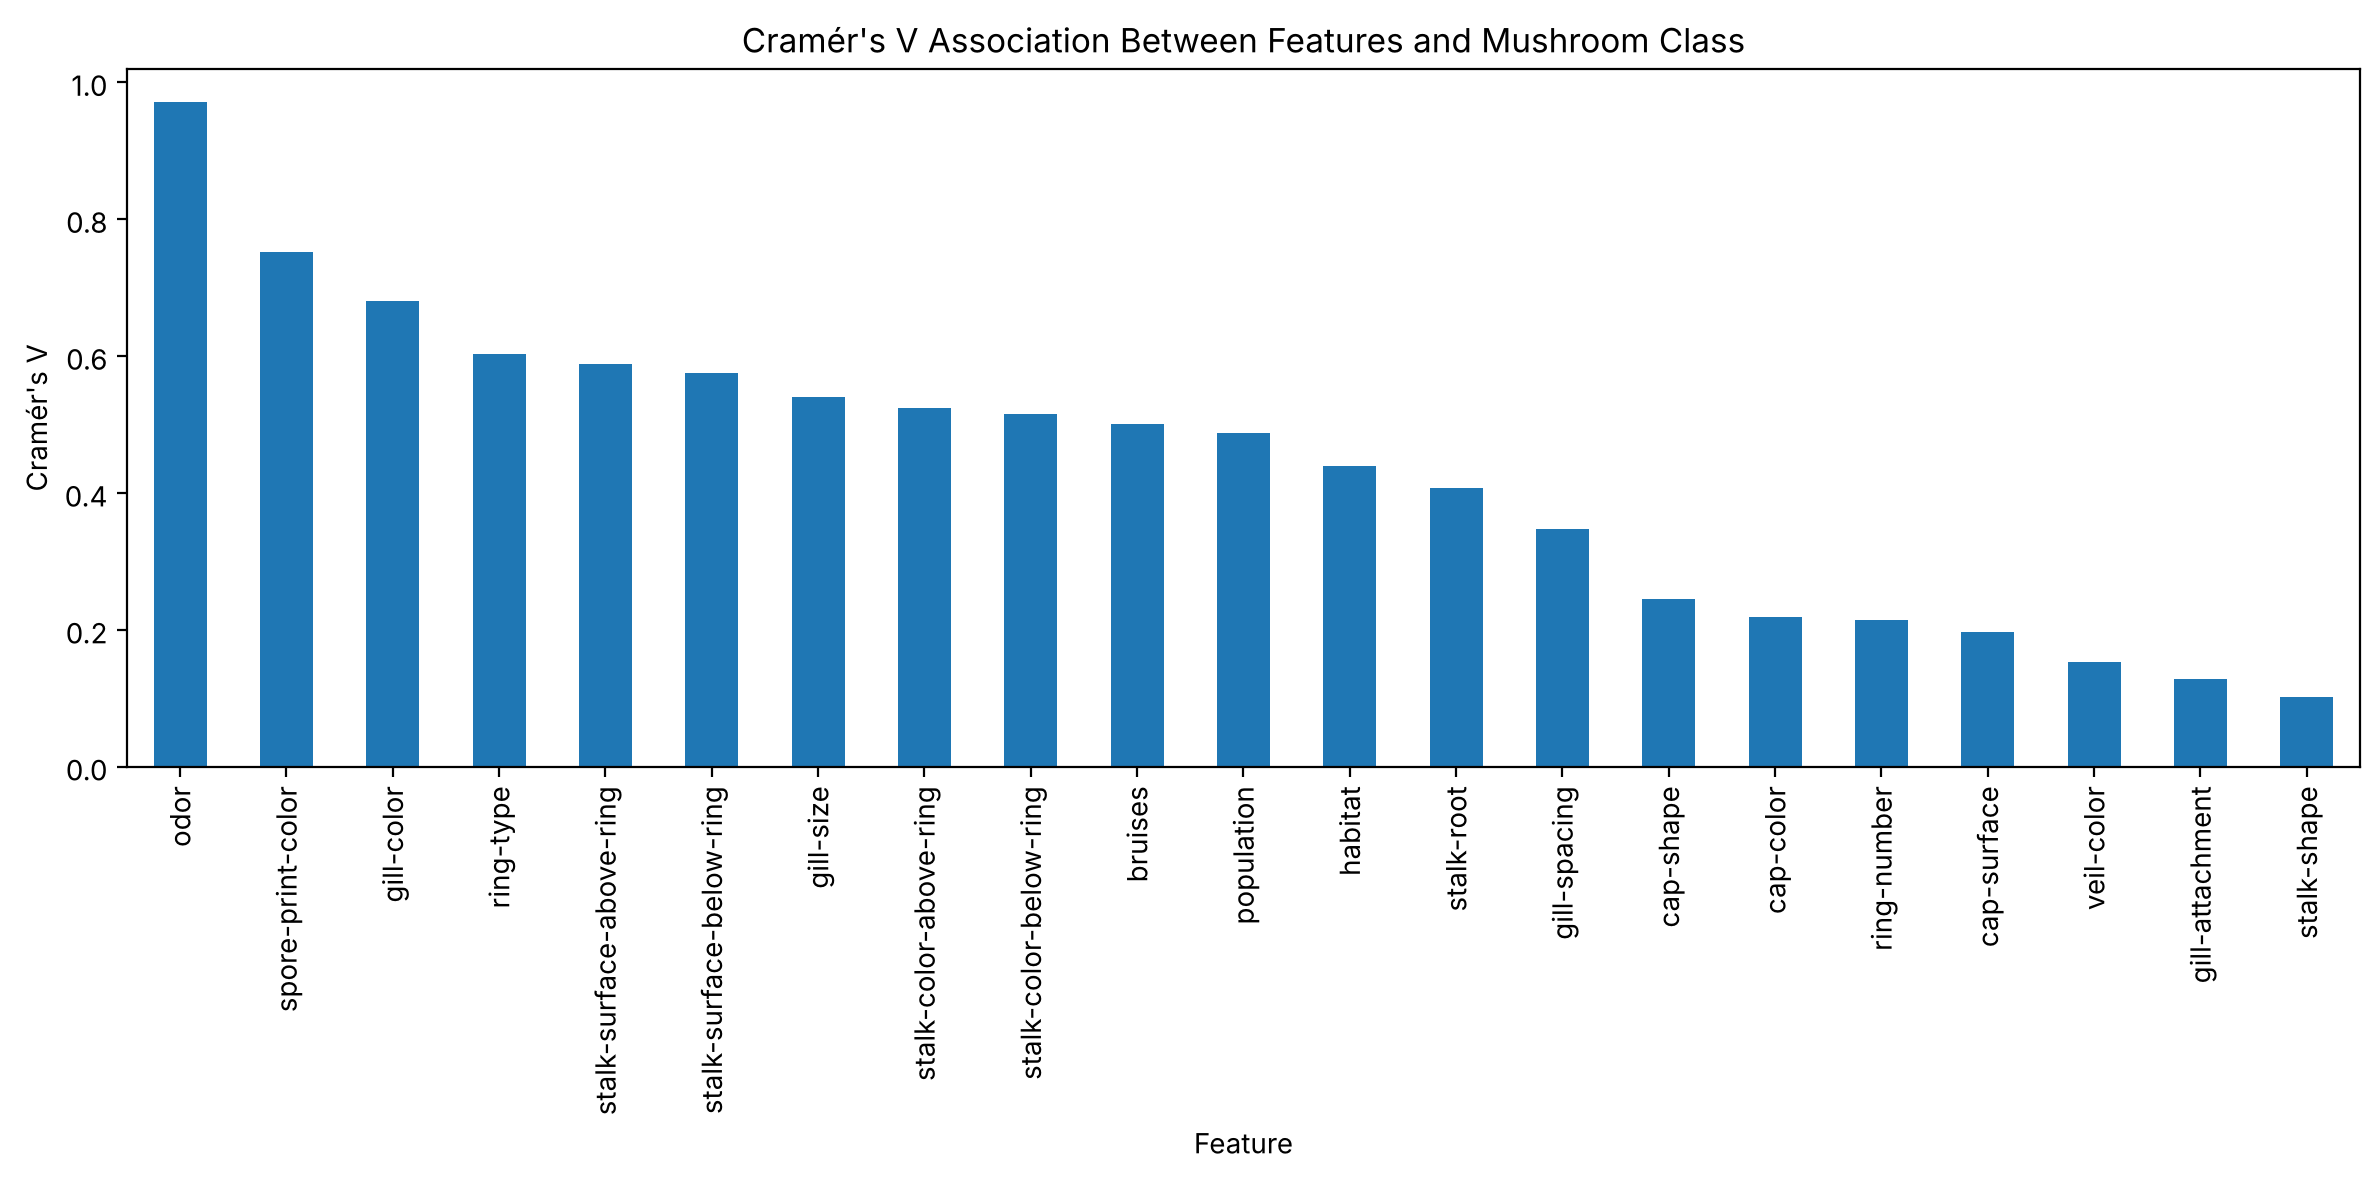

In [10]:
cramers_df.plot(
    x="Feature",
    y="Cramers_V",
    kind="bar",
    legend=False,
    figsize=(12, 6)
)

plt.title("Cramér's V Association Between Features and Mushroom Class")
plt.xlabel("Feature")
plt.ylabel("Cramér's V")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

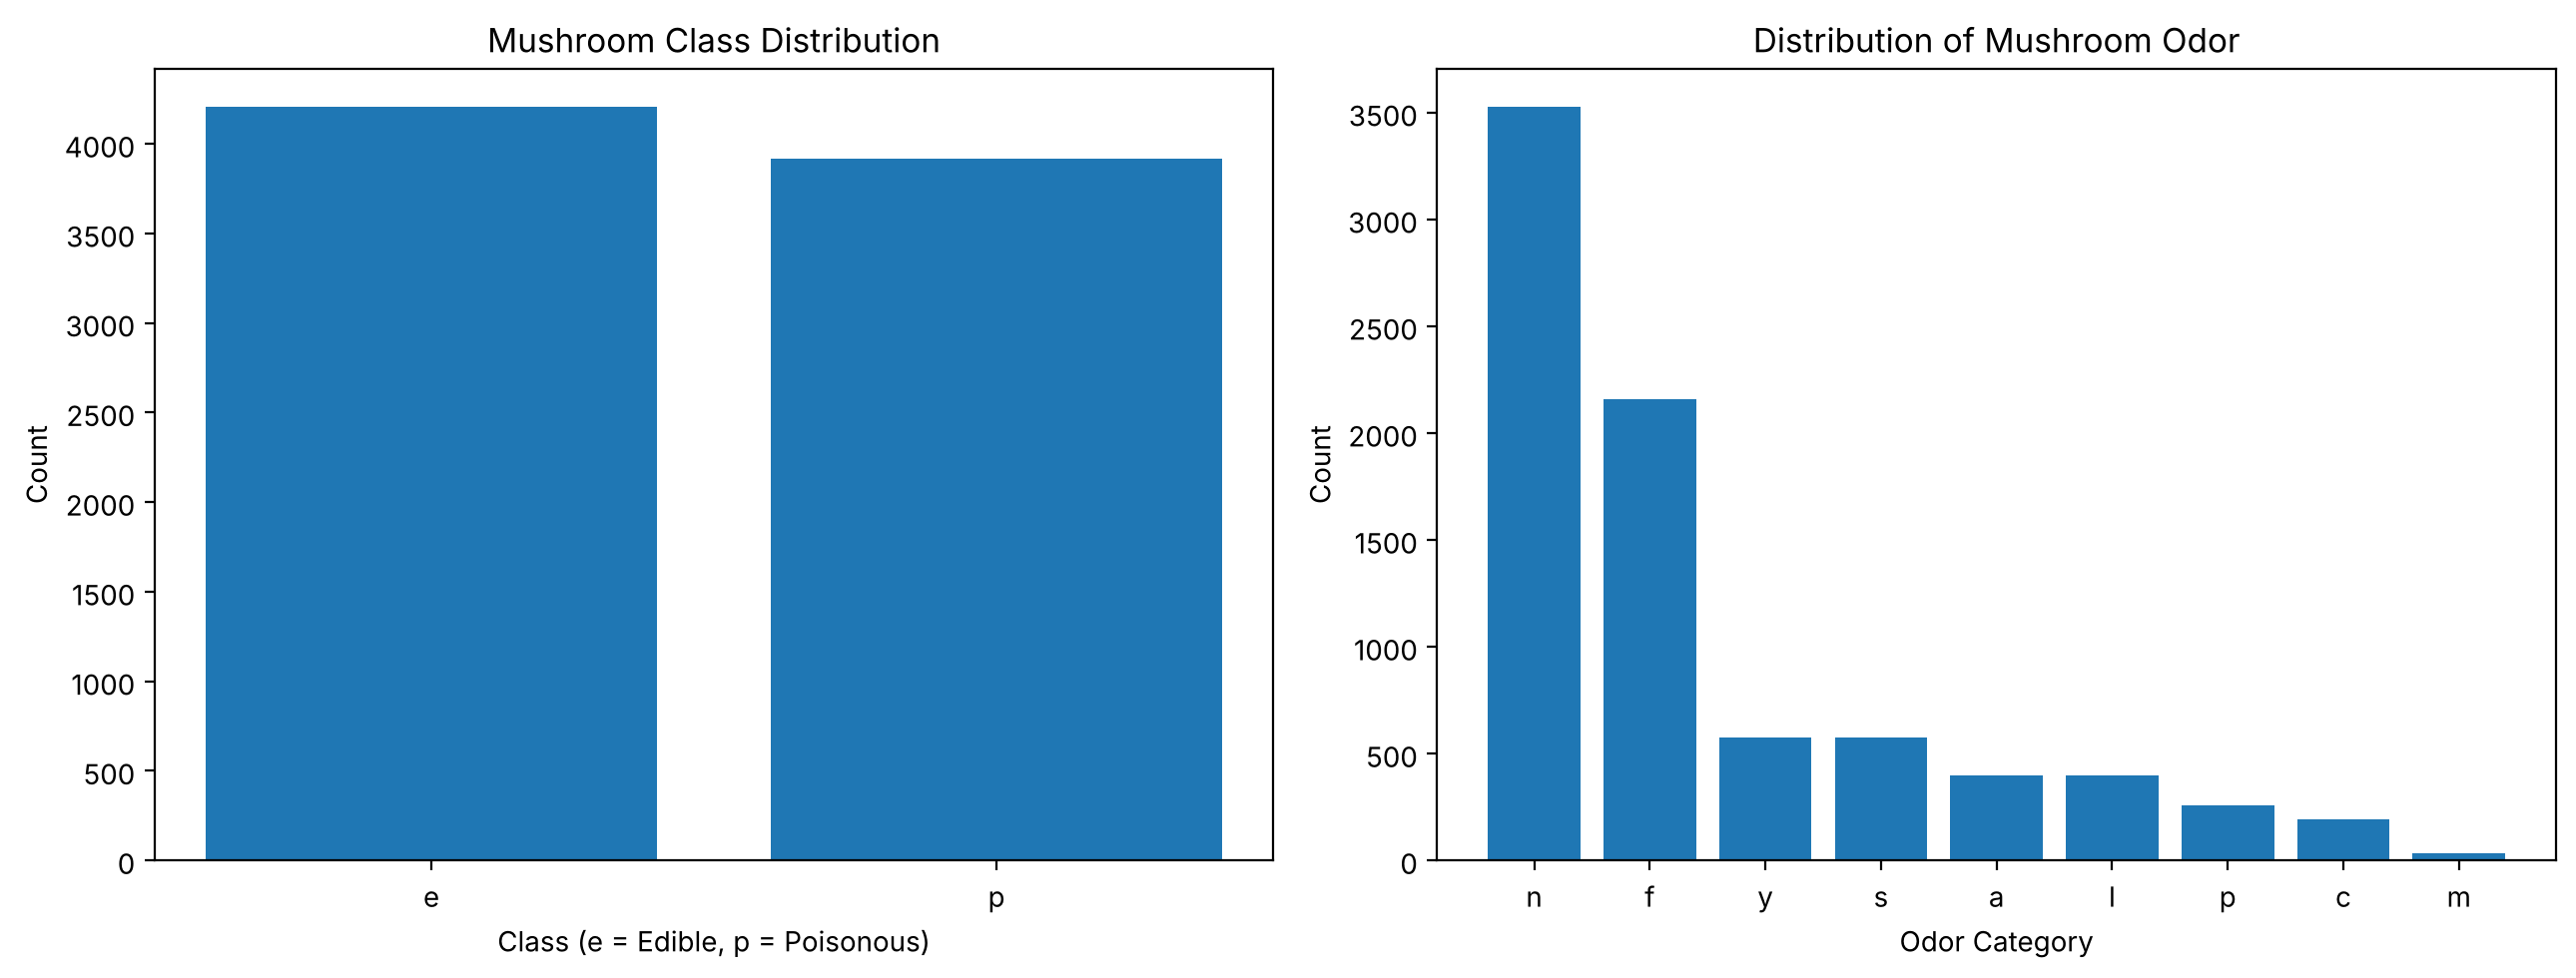

In [11]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Class distribution
class_counts = df["class"].value_counts()

axes[0].bar(class_counts.index, class_counts.values)
axes[0].set_title("Mushroom Class Distribution")
axes[0].set_xlabel("Class (e = Edible, p = Poisonous)")
axes[0].set_ylabel("Count")

# Odor distribution
odor_counts = df["odor"].value_counts()

axes[1].bar(odor_counts.index, odor_counts.values)
axes[1].set_title("Distribution of Mushroom Odor")
axes[1].set_xlabel("Odor Category")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

### 1.3 Feature Distributions by Class
Distributions of the five features most associated with the class (highest Cramér's V), split by edible (e) and poisonous (p).

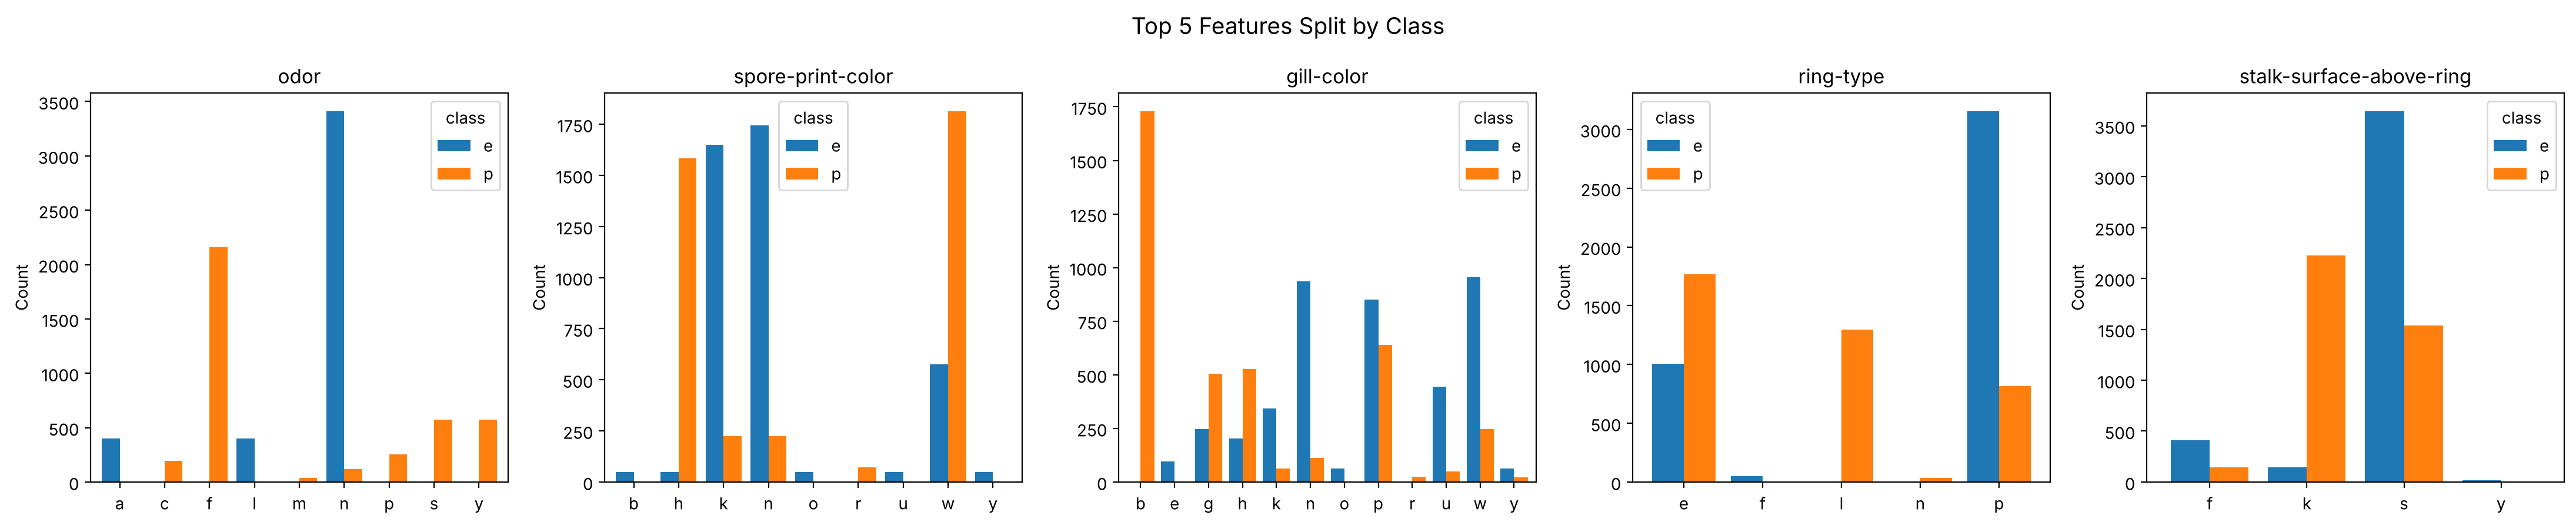

In [12]:
top5 = cramers_df["Feature"].head(5).tolist()

fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
for ax, col in zip(axes, top5):
    pd.crosstab(df[col], df["class"]).plot(kind="bar", ax=ax, width=0.8)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Count")
    ax.tick_params(axis="x", rotation=0)
plt.suptitle("Top 5 Features Split by Class", fontsize=14)
plt.tight_layout()
plt.show()

### 1.4 Feature-to-Feature Association (Cramér's V Heatmap)
Pearson correlation is not valid for categorical data, so Cramér's V is used between every pair of features. High values show redundant features (multicollinearity).

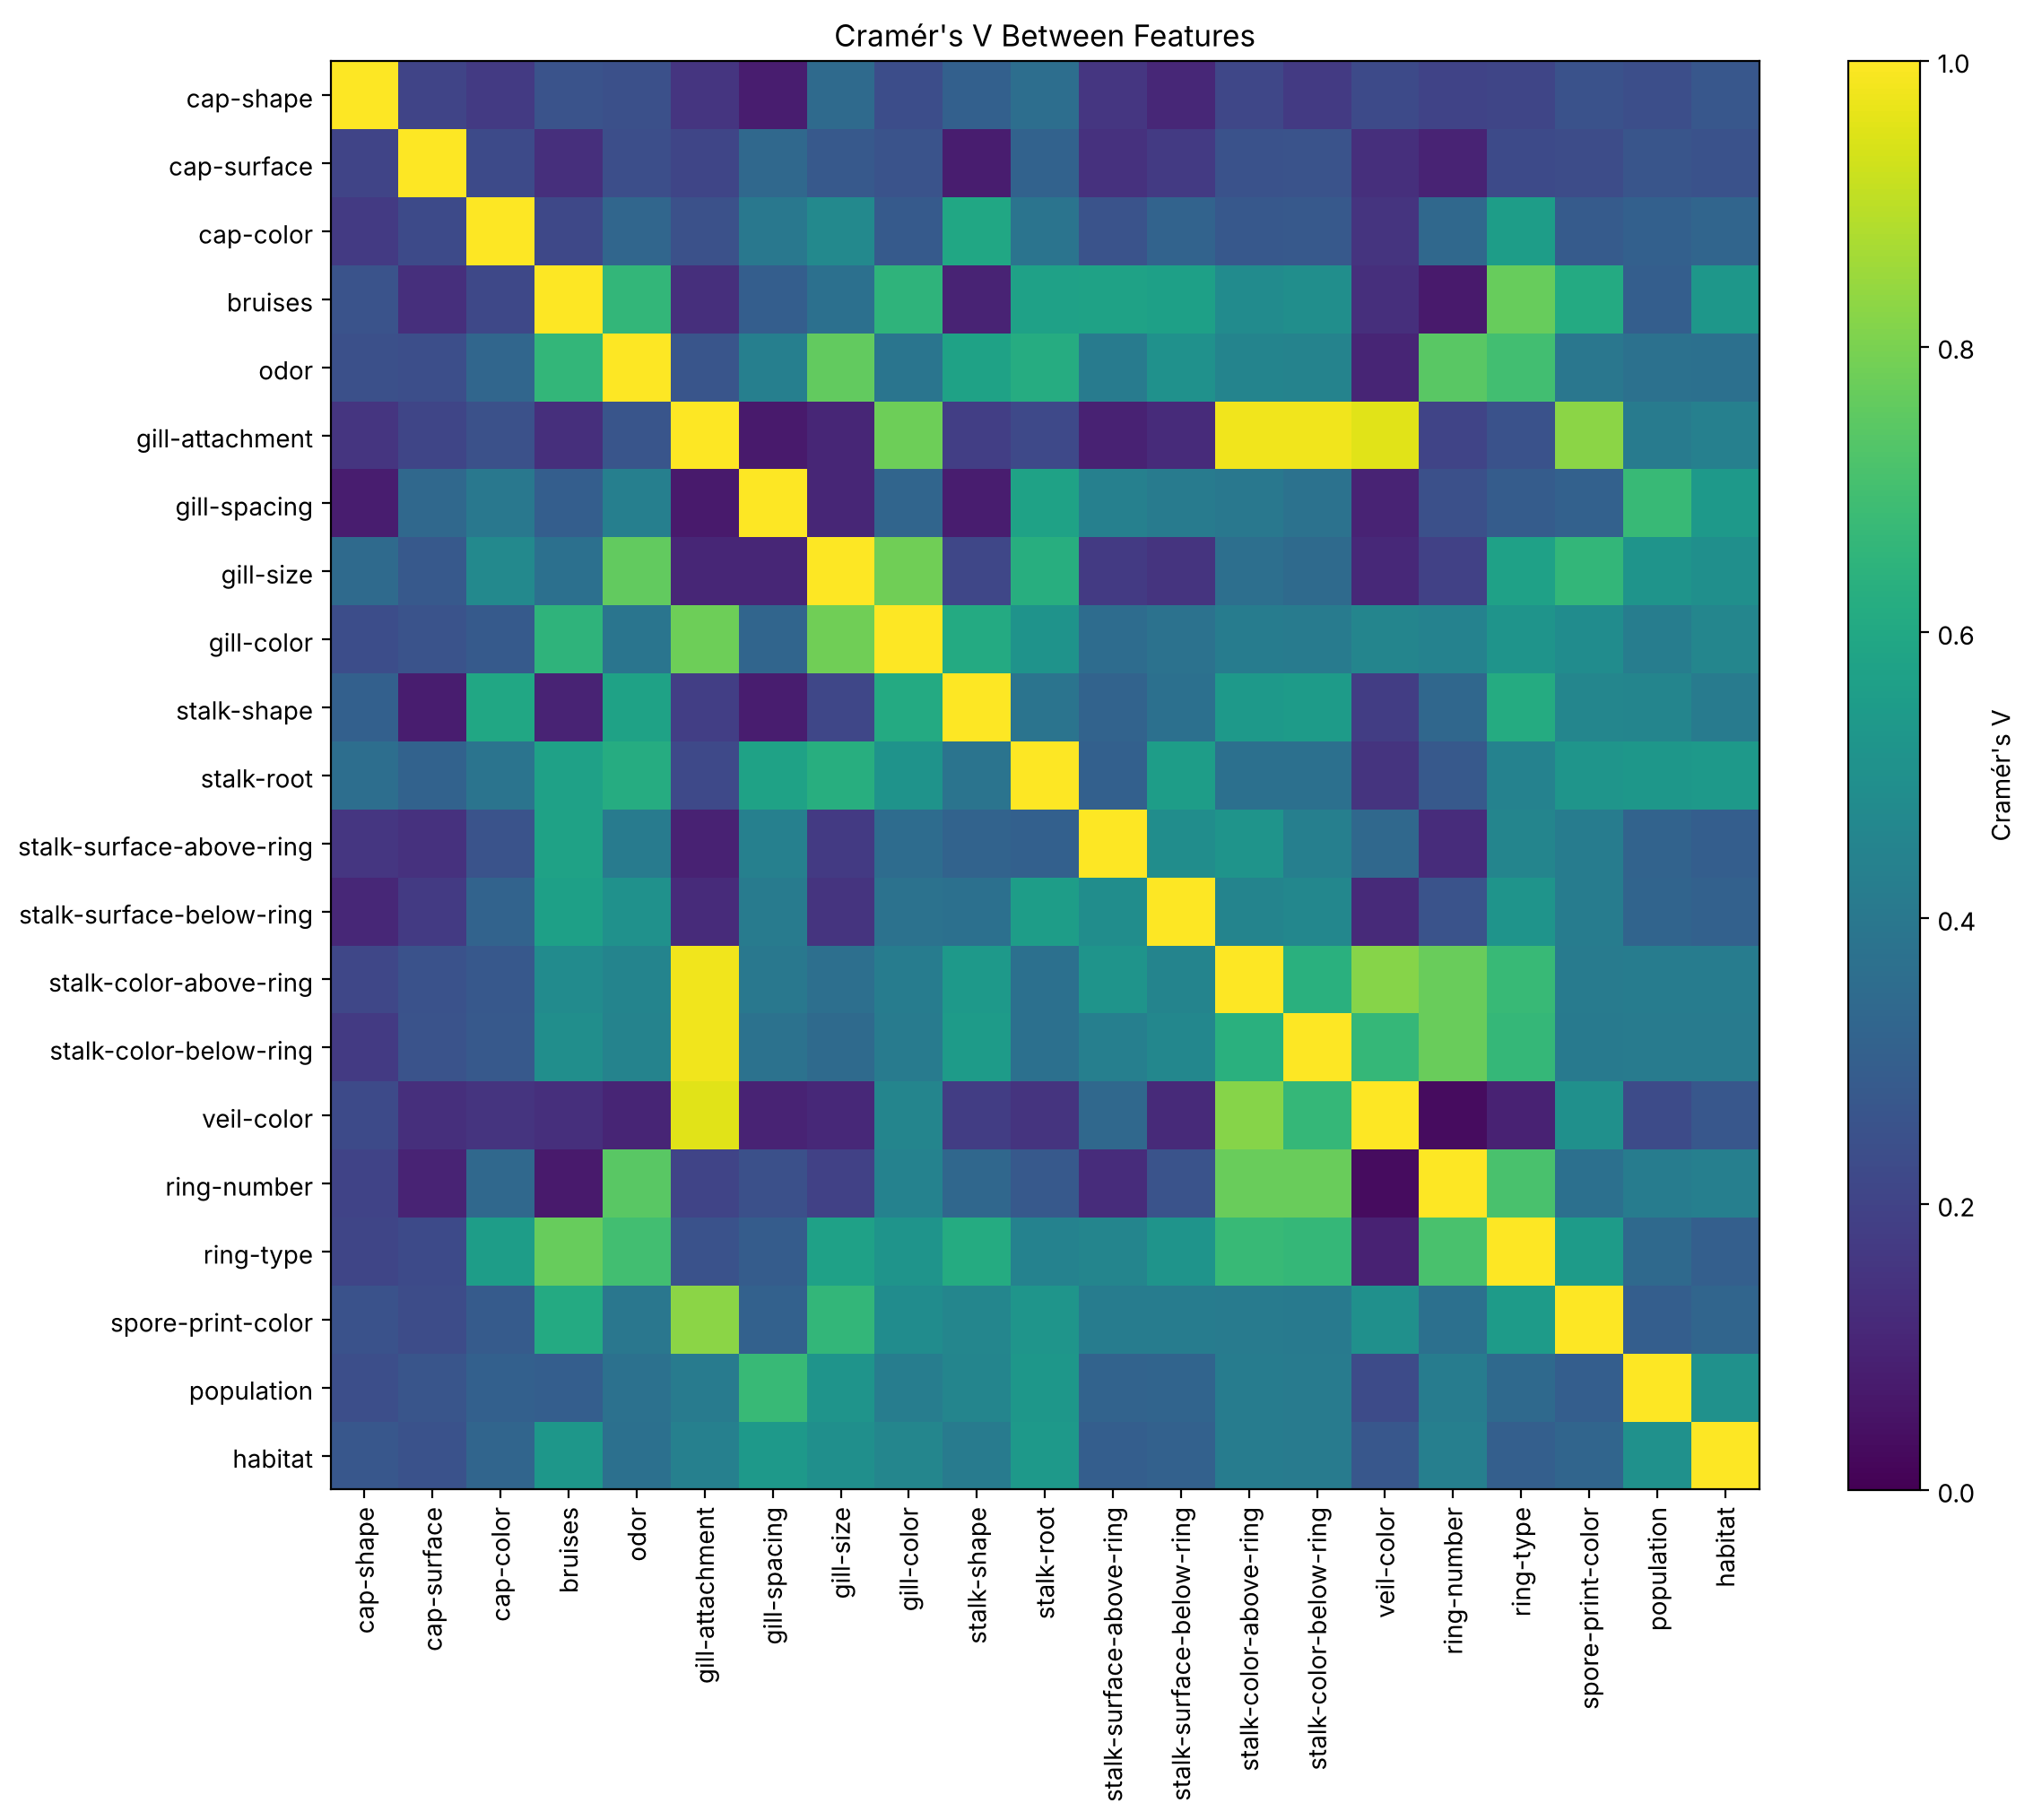

Most strongly associated feature pairs:
gill-attachment         stalk-color-above-ring    0.978
                        stalk-color-below-ring    0.978
                        veil-color                0.955
                        spore-print-color         0.827
stalk-color-above-ring  veil-color                0.816
gill-size               gill-color                0.784
gill-attachment         gill-color                0.780
stalk-color-below-ring  ring-number               0.772
dtype: float64


In [13]:
features = [c for c in df.columns if c not in ("class", "veil-type")]

assoc = pd.DataFrame(index=features, columns=features, dtype=float)
for a in features:
    for b in features:
        assoc.loc[a, b] = 1.0 if a == b else cramers_v(df[a], df[b])

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(assoc.values, cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(len(features)))
ax.set_xticklabels(features, rotation=90)
ax.set_yticks(range(len(features)))
ax.set_yticklabels(features)
fig.colorbar(im, ax=ax, label="Cramér's V")
ax.set_title("Cramér's V Between Features")
plt.tight_layout()
plt.show()

pairs = (assoc.where(np.triu(np.ones(assoc.shape, dtype=bool), k=1))
              .stack().sort_values(ascending=False))
print("Most strongly associated feature pairs:")
print(pairs.head(8).round(3))

## 2. Data Cleaning and Preprocessing

In [14]:
# Make a copy so the original raw dataset stays unchanged
df_clean = df.copy()

# Replace "?" with NaN in stalk-root
df_clean["stalk-root"] = df_clean["stalk-root"].replace("?", np.nan)

print(df_clean["stalk-root"].isnull().sum())

2480


In [15]:
print(df_clean["stalk-root"].value_counts(dropna=False))

stalk-root
b      3776
NaN    2480
e      1120
c       556
r       192
Name: count, dtype: int64


In [16]:
# Remove zero-variance feature
df_clean = df_clean.drop(columns=["veil-type"])

print("New shape:", df_clean.shape)

New shape: (8124, 22)


In [17]:
# Check missing values and unusual symbols

print("DATA QUALITY CHECK")
print("-" * 40)

print("\nMissing values:")
print(df_clean.isnull().sum())

print("\nQuestion mark values:")
print((df_clean == "?").sum())

print("\nUnique values per column:")
print(df_clean.nunique())

DATA QUALITY CHECK
----------------------------------------

Missing values:
class                          0
cap-shape                      0
cap-surface                    0
cap-color                      0
bruises                        0
odor                           0
gill-attachment                0
gill-spacing                   0
gill-size                      0
gill-color                     0
stalk-shape                    0
stalk-root                  2480
stalk-surface-above-ring       0
stalk-surface-below-ring       0
stalk-color-above-ring         0
stalk-color-below-ring         0
veil-color                     0
ring-number                    0
ring-type                      0
spore-print-color              0
population                     0
habitat                        0
dtype: int64

Question mark values:
class                       0
cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
odor       

In [18]:
X = df_clean.drop(columns=["class"])
y = df_clean["class"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

X shape: (8124, 21)
y shape: (8124,)

Target distribution:
class
e    4208
p    3916
Name: count, dtype: int64


## 3. Train-Test Split

In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True))

Training set: (6499, 21)
Test set: (1625, 21)

Training target distribution:
class
e    0.517926
p    0.482074
Name: proportion, dtype: float64

Test target distribution:
class
e    0.518154
p    0.481846
Name: proportion, dtype: float64


In [20]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

categorical_features = X.columns.tolist()

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="missing"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer([
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [21]:
# Final missing-value verification

question_marks = (df_clean == "?").sum().sum()
missing_values = df_clean.isna().sum().sum()

print("Remaining '?' symbols:", question_marks)
print("Missing values in cleaned dataset:", missing_values)

# Check the data after preprocessing
X_train_processed = preprocessor.fit_transform(X_train)

print("Preprocessing completed successfully!")
print("Processed training data shape:", X_train_processed.shape)

Remaining '?' symbols: 0
Missing values in cleaned dataset: 2480


Preprocessing completed successfully!
Processed training data shape: (6499, 116)


In [22]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (6499, 21)
X_test: (1625, 21)
y_train: (6499,)
y_test: (1625,)


## 4. Machine Learning Models

In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

logreg_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

logreg_pipeline.fit(X_train, y_train)

print("Logistic Regression trained.")

Logistic Regression trained.


In [24]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

y_pred_logreg = logreg_pipeline.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_logreg))
print("Precision:", precision_score(y_test, y_pred_logreg, pos_label="p"))
print("Recall:", recall_score(y_test, y_pred_logreg, pos_label="p"))
print("F1-score:", f1_score(y_test, y_pred_logreg, pos_label="p"))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_logreg))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_logreg))

Accuracy: 0.9993846153846154
Precision: 1.0
Recall: 0.9987228607918263
F1-score: 0.9993610223642172

Classification Report:
              precision    recall  f1-score   support

           e       1.00      1.00      1.00       842
           p       1.00      1.00      1.00       783

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625


Confusion Matrix:
[[842   0]
 [  1 782]]


In [25]:
train_pred_logreg = logreg_pipeline.predict(X_train)

print("Training Accuracy:",
      accuracy_score(y_train, train_pred_logreg))

print("Testing Accuracy:",
      accuracy_score(y_test, y_pred_logreg))

Training Accuracy:

 0.9998461301738729
Testing Accuracy: 0.9993846153846154


In [26]:
from sklearn.tree import DecisionTreeClassifier

tree_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(
        random_state=42
    ))
])

tree_pipeline.fit(X_train, y_train)

y_pred_tree = tree_pipeline.predict(X_test)

print("Accuracy:",
      accuracy_score(y_test, y_pred_tree))

print("Precision:",
      precision_score(y_test, y_pred_tree, pos_label="p"))

print("Recall:",
      recall_score(y_test, y_pred_tree, pos_label="p"))

print("F1-score:",
      f1_score(y_test, y_pred_tree, pos_label="p"))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tree))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0

Confusion Matrix:
[[842   0]
 [  0 783]]


In [27]:
train_pred_tree = tree_pipeline.predict(X_train)

print("Training Accuracy:",
      accuracy_score(y_train, train_pred_tree))

print("Testing Accuracy:",
      accuracy_score(y_test, y_pred_tree))

Training Accuracy: 1.0
Testing Accuracy: 1.0


In [28]:
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

rf_pipeline.fit(X_train, y_train)

y_pred_rf = rf_pipeline.predict(X_test)

print("Accuracy:",
      accuracy_score(y_test, y_pred_rf))

print("Precision:",
      precision_score(y_test, y_pred_rf, pos_label="p"))

print("Recall:",
      recall_score(y_test, y_pred_rf, pos_label="p"))

print("F1-score:",
      f1_score(y_test, y_pred_rf, pos_label="p"))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0

Confusion Matrix:
[[842   0]
 [  0 783]]


In [29]:
train_pred_rf = rf_pipeline.predict(X_train)

print("Training Accuracy:",
      accuracy_score(y_train, train_pred_rf))

print("Testing Accuracy:",
      accuracy_score(y_test, y_pred_rf))

Training Accuracy: 1.0
Testing Accuracy: 1.0


## 5. Cross-Validation and Hyperparameter Tuning

In [30]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "Logistic Regression": logreg_pipeline,
    "Decision Tree": tree_pipeline,
    "Random Forest": rf_pipeline
}

for name, model in models.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy"
    )

    print(f"\n{name}")
    print("Fold scores:", scores)
    print("Mean CV accuracy:", scores.mean())
    print("Std:", scores.std())


Logistic Regression
Fold scores: [0.99692308 1.         1.         1.         1.        ]
Mean CV accuracy: 0.9993846153846153
Std: 0.0012307692307692351

Decision Tree
Fold scores: [0.99846154 1.         1.         1.         1.        ]
Mean CV accuracy: 0.9996923076923077
Std: 0.0006153846153845955



Random Forest
Fold scores: [1. 1. 1. 1. 1.]
Mean CV accuracy: 1.0
Std: 0.0


In [31]:
from sklearn.model_selection import GridSearchCV

logreg_param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__solver": ["liblinear", "lbfgs"]
}

logreg_grid = GridSearchCV(
    estimator=logreg_pipeline,
    param_grid=logreg_param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

logreg_grid.fit(X_train, y_train)

print("Best parameters:")
print(logreg_grid.best_params_)

print("\nBest CV accuracy:")
print(logreg_grid.best_score_)

Best parameters:
{'model__C': 100, 'model__solver': 'lbfgs'}

Best CV accuracy:
1.0


In [32]:
best_logreg = logreg_grid.best_estimator_

y_pred_logreg_tuned = best_logreg.predict(X_test)

print("Test Accuracy:",
      accuracy_score(y_test, y_pred_logreg_tuned))

print("Precision:",
      precision_score(y_test, y_pred_logreg_tuned, pos_label="p"))

print("Recall:",
      recall_score(y_test, y_pred_logreg_tuned, pos_label="p"))

print("F1-score:",
      f1_score(y_test, y_pred_logreg_tuned, pos_label="p"))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_logreg_tuned))

Test Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0

Confusion Matrix:
[[842   0]
 [  0 783]]


In [33]:
tree_param_grid = {
    "model__criterion": ["gini", "entropy"],
    "model__max_depth": [None, 3, 5, 10, 20],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4]
}

tree_grid = GridSearchCV(
    estimator=tree_pipeline,
    param_grid=tree_param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

tree_grid.fit(X_train, y_train)

print("Best parameters:")
print(tree_grid.best_params_)

print("\nBest CV accuracy:")
print(tree_grid.best_score_)

Best parameters:
{'model__criterion': 'gini', 'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}

Best CV accuracy:
0.9996923076923077


In [34]:
best_tree = tree_grid.best_estimator_

y_pred_tree_tuned = best_tree.predict(X_test)

print("Test Accuracy:",
      accuracy_score(y_test, y_pred_tree_tuned))

print("Precision:",
      precision_score(y_test, y_pred_tree_tuned, pos_label="p"))

print("Recall:",
      recall_score(y_test, y_pred_tree_tuned, pos_label="p"))

print("F1-score:",
      f1_score(y_test, y_pred_tree_tuned, pos_label="p"))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tree_tuned))

Test Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0

Confusion Matrix:
[[842   0]
 [  0 783]]


In [35]:
rf_param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 5, 10, 20],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2"]
}

rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print("Best parameters:")
print(rf_grid.best_params_)

print("\nBest CV accuracy:")
print(rf_grid.best_score_)

Best parameters:
{'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 100}

Best CV accuracy:
1.0


In [36]:
best_rf = rf_grid.best_estimator_

y_pred_rf_tuned = best_rf.predict(X_test)

print("Test Accuracy:",
      accuracy_score(y_test, y_pred_rf_tuned))

print("Precision:",
      precision_score(y_test, y_pred_rf_tuned, pos_label="p"))

print("Recall:",
      recall_score(y_test, y_pred_rf_tuned, pos_label="p"))

print("F1-score:",
      f1_score(y_test, y_pred_rf_tuned, pos_label="p"))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf_tuned))

Test Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0

Confusion Matrix:
[[842   0]
 [  0 783]]


### 5.1 Tuning Summary: Before vs After
Accuracy is already at or near 1.0 for most settings, so many grid points **tie** and `GridSearchCV` simply returns the first one. Log-loss is added below because it also measures how *confident* the probabilities are, so it can still separate models when accuracy cannot.

In [37]:
from sklearn.model_selection import cross_validate

tuning_pairs = {
    "Logistic Regression": (logreg_pipeline, logreg_grid),
    "Decision Tree": (tree_pipeline, tree_grid),
    "Random Forest": (rf_pipeline, rf_grid),
}

tuning_rows = []
for name, (default_model, grid) in tuning_pairs.items():
    row = {"Model": name, "Best Params": grid.best_params_}
    for label, model in [("Default", default_model), ("Tuned", grid.best_estimator_)]:
        cvres = cross_validate(model, X_train, y_train, cv=cv,
                               scoring=["accuracy", "neg_log_loss"], n_jobs=-1)
        row[f"{label} CV Acc"] = round(cvres["test_accuracy"].mean(), 5)
        row[f"{label} CV LogLoss"] = round(-cvres["test_neg_log_loss"].mean(), 5)
        row[f"{label} Test Errors"] = int((model.predict(X_test) != y_test).sum())
    n_ties = (grid.cv_results_["mean_test_score"] == grid.best_score_).sum()
    row["Grid Points Tied at Best"] = f"{n_ties} / {len(grid.cv_results_['params'])}"
    tuning_rows.append(row)

tuning_df = pd.DataFrame(tuning_rows)
pd.set_option("display.max_colwidth", 120)
tuning_df

,Model,Best Params,Default CV Acc,Default CV LogLoss,Default Test Errors,Tuned CV Acc,Tuned CV LogLoss,Tuned Test Errors,Grid Points Tied at Best
0,Logistic Regression,"{'model__C': 100, 'model__solver': 'lbfgs'}",0.99938,0.00766,1,1.00000,0.00067,0,1 / 10
1,Decision Tree,"{'model__criterion': 'gini', 'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}",0.99969,0.01109,0,0.99969,0.01109,0,24 / 90
2,Random Forest,"{'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__min_samples_split': ...",1.00000,0.00076,0,1.00000,0.00076,0,52 / 216


## 6. Ensemble Learning

In [38]:
from sklearn.ensemble import VotingClassifier

ensemble_model = VotingClassifier(
    estimators=[
        ("logistic_regression", logreg_grid.best_estimator_),
        ("random_forest", rf_grid.best_estimator_)
    ],
    voting="soft"
)

ensemble_model.fit(X_train, y_train)

print("Ensemble model trained successfully!")

Ensemble model trained successfully!


In [39]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Predict using the ensemble model
y_pred_ensemble = ensemble_model.predict(X_test)

# Calculate evaluation metrics
print("Ensemble Model Evaluation")
print("-------------------------")

print("Test Accuracy:", accuracy_score(y_test, y_pred_ensemble))
print("Precision:", precision_score(y_test, y_pred_ensemble, pos_label="p"))
print("Recall:", recall_score(y_test, y_pred_ensemble, pos_label="p"))
print("F1-score:", f1_score(y_test, y_pred_ensemble, pos_label="p"))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_ensemble, labels=["e", "p"]))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_ensemble))

Ensemble Model Evaluation
-------------------------
Test Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0

Confusion Matrix:
[[842   0]
 [  0 783]]

Classification Report:
              precision    recall  f1-score   support

           e       1.00      1.00      1.00       842
           p       1.00      1.00      1.00       783

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625



## 7. Model Evaluation and Comparison

In [40]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

models_to_compare = {
    "Logistic Regression": logreg_grid.best_estimator_,
    "Decision Tree": tree_grid.best_estimator_,
    "Random Forest": rf_grid.best_estimator_,
    "Ensemble (Soft Voting)": ensemble_model
}

results = []

for name, model in models_to_compare.items():
    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, pos_label="p"),
        "Recall": recall_score(y_test, y_pred, pos_label="p"),
        "F1-score": f1_score(y_test, y_pred, pos_label="p")
    })

comparison_df = pd.DataFrame(results)

print("Final Model Comparison:")
display(comparison_df)

Final Model Comparison:


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,1.0,1.0,1.0,1.0
1,Decision Tree,1.0,1.0,1.0,1.0
2,Random Forest,1.0,1.0,1.0,1.0
3,Ensemble (Soft Voting),1.0,1.0,1.0,1.0


In [41]:
import pandas as pd
import time

efficiency_results = []

for name, model in models_to_compare.items():

    # Calculate training and testing accuracy
    train_accuracy = model.score(X_train, y_train)
    test_accuracy = model.score(X_test, y_test)

    # Measure prediction time
    start_time = time.perf_counter()

    predictions = model.predict(X_test)

    end_time = time.perf_counter()

    prediction_time = (end_time - start_time) * 1000

    efficiency_results.append({
        "Model": name,
        "Train Accuracy": train_accuracy,
        "Test Accuracy": test_accuracy,
        "Overfitting Gap": train_accuracy - test_accuracy,
        "Prediction Time (ms)": round(prediction_time, 3)
    })

efficiency_df = pd.DataFrame(efficiency_results)

print("Model Efficiency and Overfitting Comparison:")
display(efficiency_df)

Model Efficiency and Overfitting Comparison:


,Model,Train Accuracy,Test Accuracy,Overfitting Gap,Prediction Time (ms)
0,Logistic Regression,1.0,1.0,0.0,6.449
1,Decision Tree,1.0,1.0,0.0,6.493
2,Random Forest,1.0,1.0,0.0,15.417
3,Ensemble (Soft Voting),1.0,1.0,0.0,21.595


### 7.1 ROC-AUC and ROC Curves
ROC-AUC is required by the brief. The positive class is **poisonous (p)**, because missing a poisonous mushroom is the costly error.

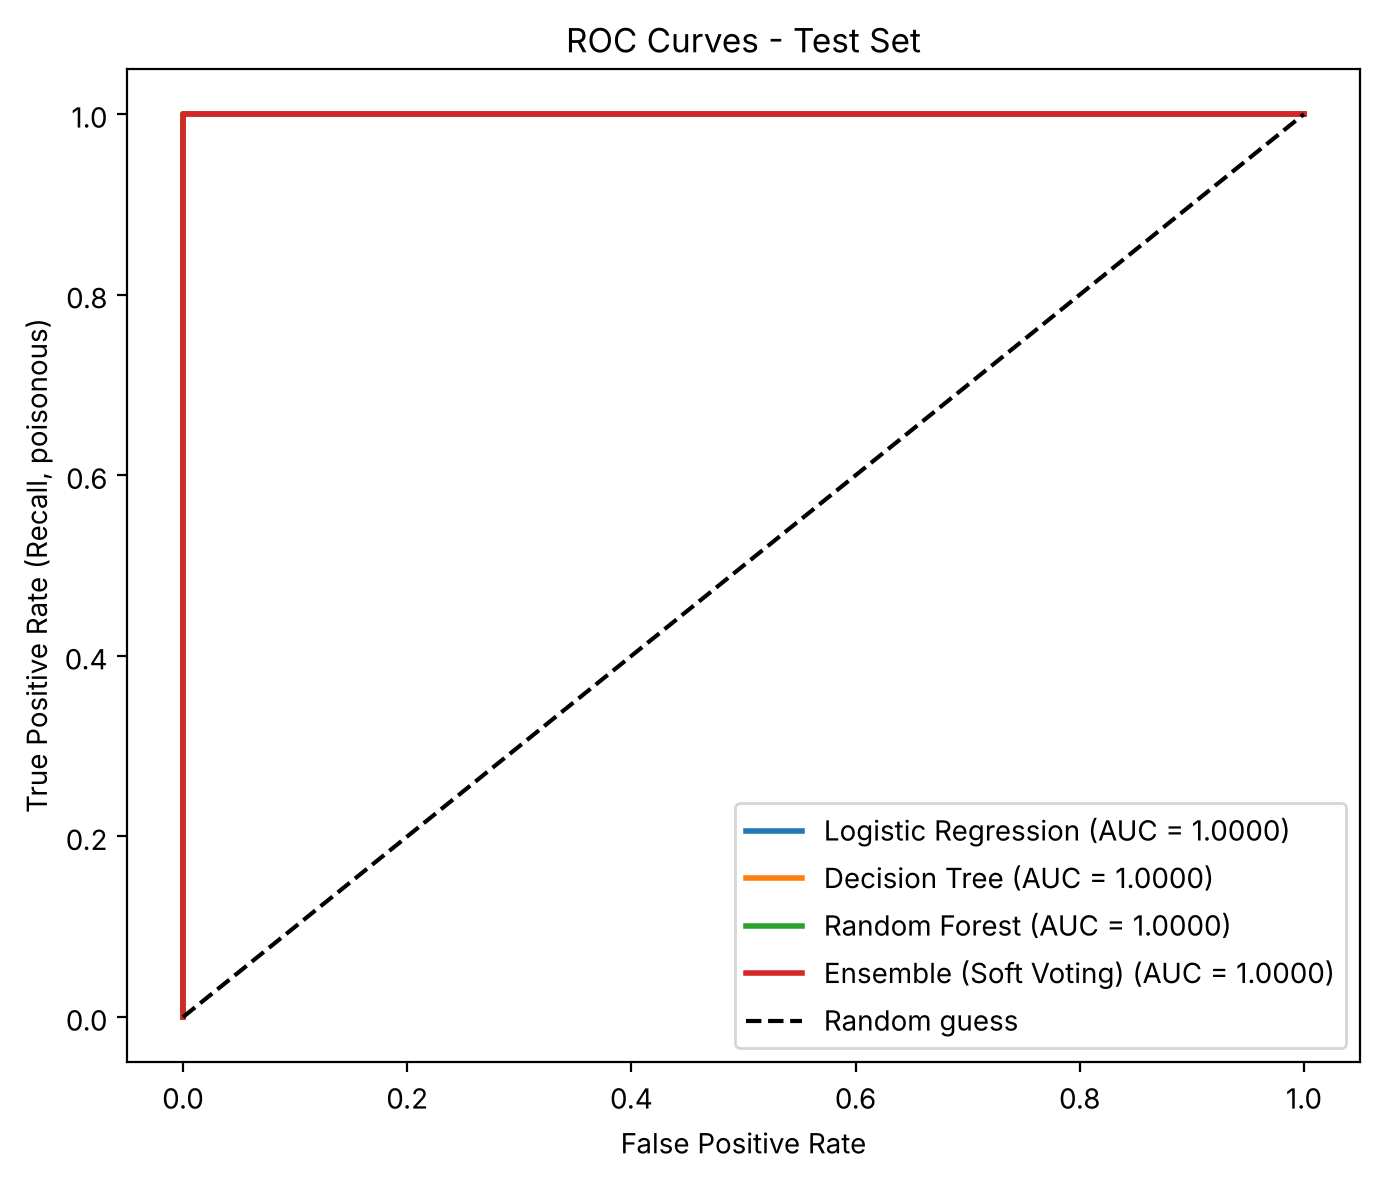

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Log-loss
0,Logistic Regression,1.0,1.0,1.0,1.0,1.0,4.011205e-04
1,Decision Tree,1.0,1.0,1.0,1.0,1.0,2.220446e-16
2,Random Forest,1.0,1.0,1.0,1.0,1.0,4.105498e-04
3,Ensemble (Soft Voting),1.0,1.0,1.0,1.0,1.0,4.039673e-04


In [42]:
from sklearn.metrics import roc_auc_score, roc_curve, log_loss

y_test_bin = (y_test == "p").astype(int)

auc_rows = []
fig, ax = plt.subplots(figsize=(7, 6))
for name, model in models_to_compare.items():
    p_idx = list(model.classes_).index("p")
    proba = model.predict_proba(X_test)[:, p_idx]
    auc = roc_auc_score(y_test_bin, proba)
    auc_rows.append({"Model": name, "ROC-AUC": auc,
                     "Log-loss": log_loss(y_test_bin, proba)})
    fpr, tpr, _ = roc_curve(y_test_bin, proba)
    ax.plot(fpr, tpr, linewidth=2, label=f"{name} (AUC = {auc:.4f})")

ax.plot([0, 1], [0, 1], "k--", label="Random guess")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate (Recall, poisonous)")
ax.set_title("ROC Curves - Test Set")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

auc_df = pd.DataFrame(auc_rows)
comparison_df = comparison_df.merge(auc_df, on="Model")
comparison_df

### 7.2 Confusion Matrices

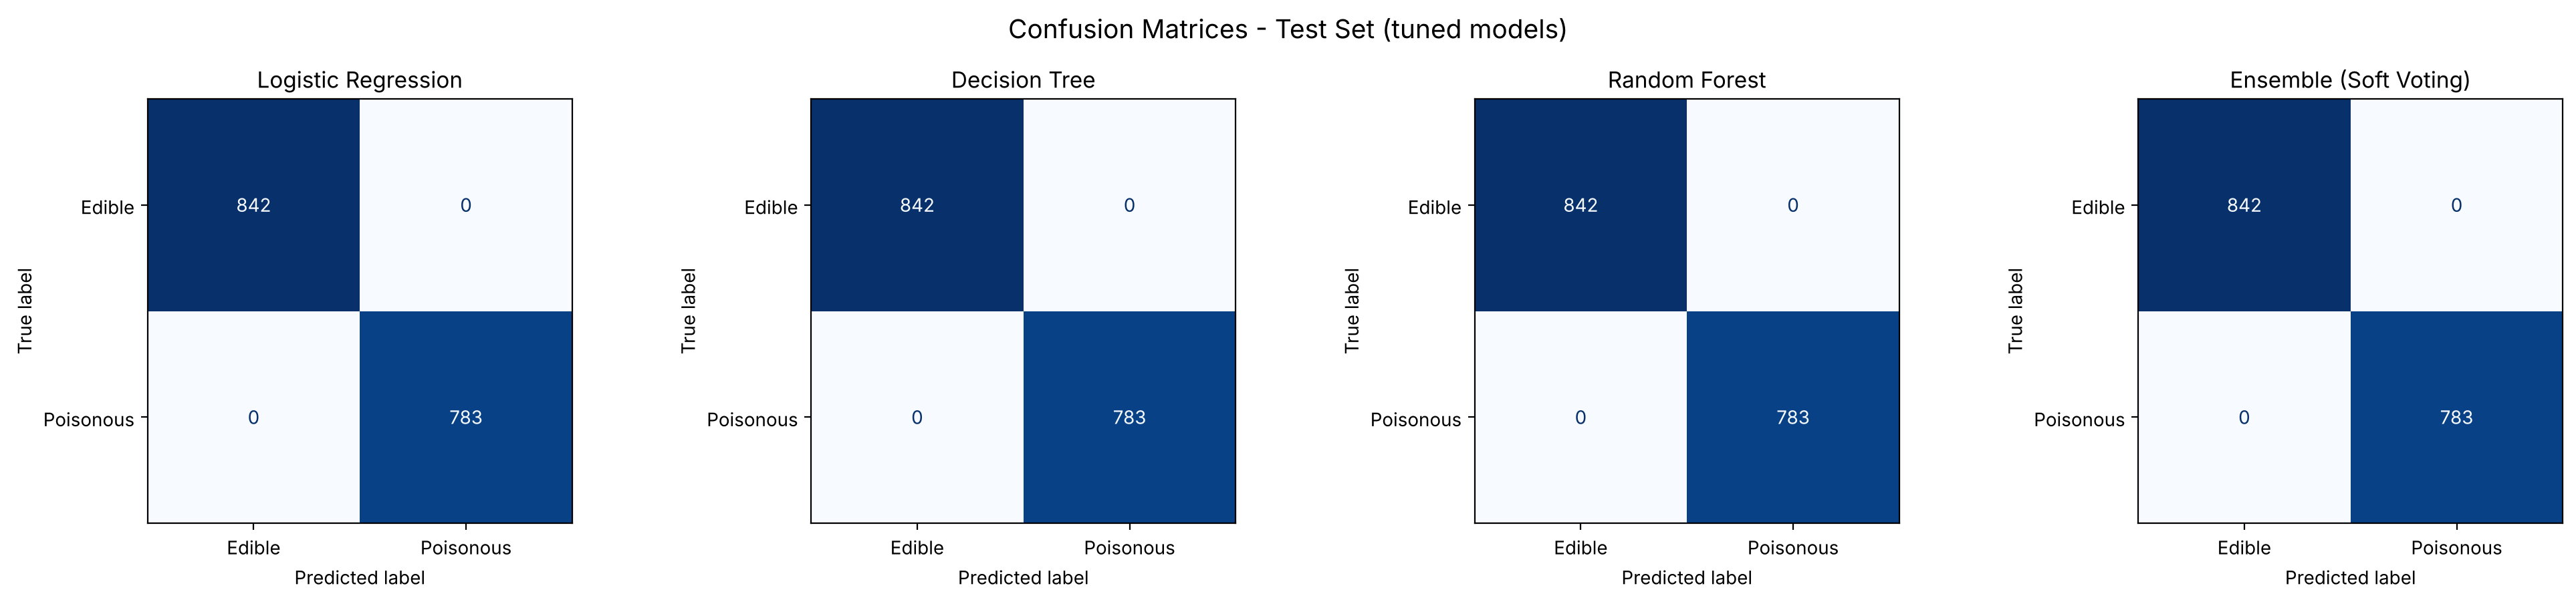

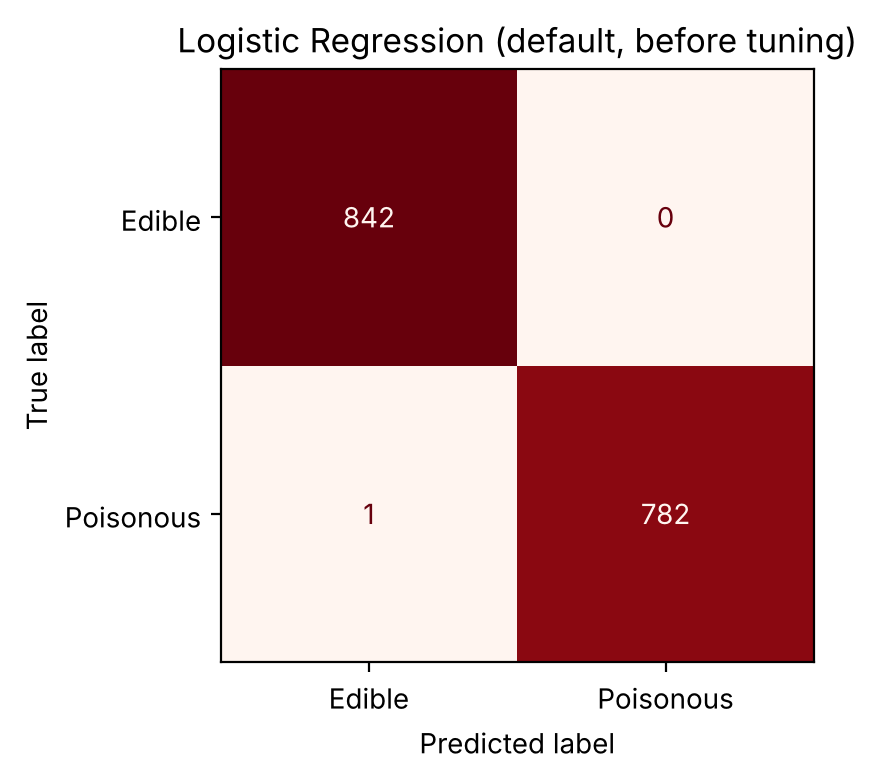

In [43]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (name, model) in zip(axes, models_to_compare.items()):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test, labels=["e", "p"],
        display_labels=["Edible", "Poisonous"], cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name)
plt.suptitle("Confusion Matrices - Test Set (tuned models)", fontsize=14)
plt.tight_layout()
plt.show()

# The untuned Logistic Regression is the only model that made a mistake
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_logreg, labels=["e", "p"],
    display_labels=["Edible", "Poisonous"], cmap="Reds", ax=ax, colorbar=False)
ax.set_title("Logistic Regression (default, before tuning)")
plt.tight_layout()
plt.show()

### 7.3 Training and Prediction Time
A single timing is noisy, so each model is refit and timed **5 times** and the median is reported.

In [44]:
from sklearn.base import clone

N_REPEATS = 5
timing_rows = []
for name, model in models_to_compare.items():
    fit_times, pred_times = [], []
    for _ in range(N_REPEATS):
        m = clone(model)
        t0 = time.perf_counter(); m.fit(X_train, y_train); fit_times.append(time.perf_counter() - t0)
        t0 = time.perf_counter(); m.predict(X_test); pred_times.append(time.perf_counter() - t0)
    timing_rows.append({
        "Model": name,
        "Median Fit Time (ms)": round(np.median(fit_times) * 1000, 1),
        "Median Predict Time (ms)": round(np.median(pred_times) * 1000, 2),
        "Predict Time per 1,000 rows (ms)": round(np.median(pred_times) * 1000 / len(X_test) * 1000, 2),
    })

timing_df = pd.DataFrame(timing_rows)
timing_df

,Model,Median Fit Time (ms),Median Predict Time (ms),"Predict Time per 1,000 rows (ms)"
0,Logistic Regression,31.9,6.67,4.11
1,Decision Tree,32.3,6.69,4.12
2,Random Forest,316.2,17.87,11.00
3,Ensemble (Soft Voting),347.9,24.58,15.12


In [45]:
# Total grid search cost (sum of every fit performed during tuning)
grid_cost = pd.DataFrame([
    {"Model": name,
     "Grid Points": len(grid.cv_results_["params"]),
     "Total Fits": len(grid.cv_results_["params"]) * cv.get_n_splits(),
     "Mean Fit Time per Fit (ms)": round(grid.cv_results_["mean_fit_time"].mean() * 1000, 1)}
    for name, (_, grid) in tuning_pairs.items()
])
grid_cost

,Model,Grid Points,Total Fits,Mean Fit Time per Fit (ms)
0,Logistic Regression,10,50,38.8
1,Decision Tree,90,450,32.2
2,Random Forest,216,1080,471.0


### 7.4 Learning Curves (Overfitting / Underfitting)
Training and validation accuracy as the training set grows. A large gap means overfitting; both curves low means underfitting.

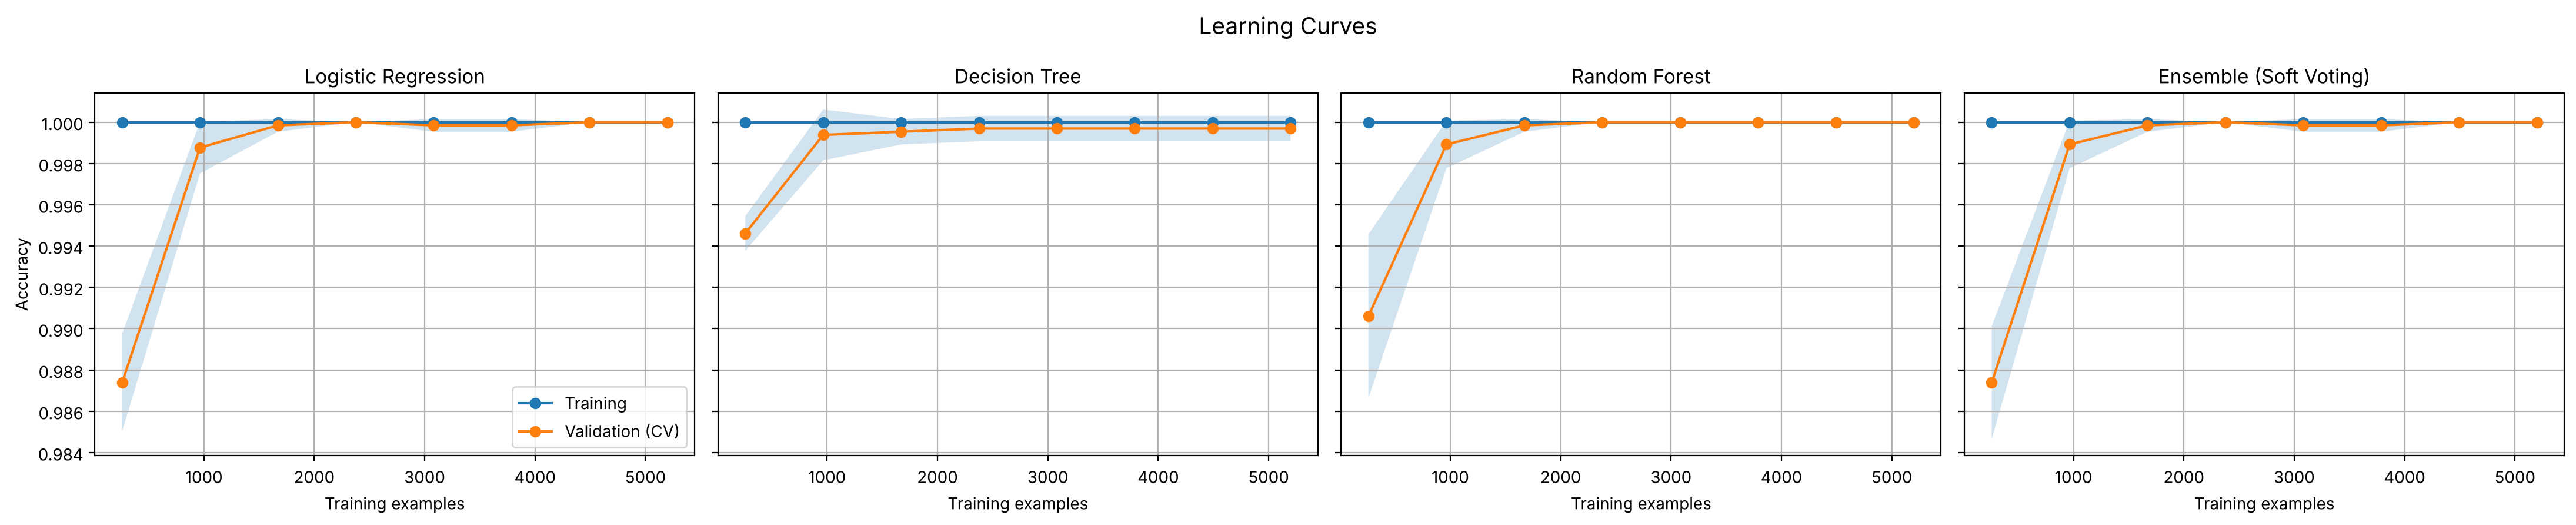

In [46]:
from sklearn.model_selection import learning_curve

train_sizes = np.linspace(0.05, 1.0, 8)

fig, axes = plt.subplots(1, 4, figsize=(22, 4.5), sharey=True)
for ax, (name, model) in zip(axes, models_to_compare.items()):
    sizes, tr, va = learning_curve(model, X_train, y_train, cv=cv,
                                   train_sizes=train_sizes, scoring="accuracy", n_jobs=-1)
    ax.plot(sizes, tr.mean(axis=1), "o-", label="Training")
    ax.plot(sizes, va.mean(axis=1), "o-", label="Validation (CV)")
    ax.fill_between(sizes, va.mean(axis=1) - va.std(axis=1),
                    va.mean(axis=1) + va.std(axis=1), alpha=0.2)
    ax.set_title(name)
    ax.set_xlabel("Training examples")
    ax.grid(True)
axes[0].set_ylabel("Accuracy")
axes[0].legend(loc="lower right")
plt.suptitle("Learning Curves", fontsize=14)
plt.tight_layout()
plt.show()

### 7.5 Does the Ensemble Significantly Improve Performance? (McNemar's Test)
McNemar's test compares two classifiers on the same test set using only the cases where they **disagree** (b = ensemble right / model wrong, c = model right / ensemble wrong). The exact binomial version is used because disagreements are very rare. H0: both models have the same error rate.

In [47]:
from scipy.stats import binomtest

def mcnemar_exact(y_true, pred_a, pred_b):
    a_right = (pred_a == y_true)
    b_right = (pred_b == y_true)
    b = int((a_right & ~b_right).sum())   # A right, B wrong
    c = int((~a_right & b_right).sum())   # A wrong, B right
    p = 1.0 if b + c == 0 else binomtest(b, b + c, 0.5).pvalue
    return b, c, p

ens_pred = ensemble_model.predict(X_test)
mcnemar_rows = []
for name, model in list(models_to_compare.items())[:3]:
    b, c, p = mcnemar_exact(y_test.values, ens_pred, model.predict(X_test))
    mcnemar_rows.append({"Ensemble vs": name, "Ensemble right / model wrong": b,
                         "Model right / ensemble wrong": c, "p-value": p,
                         "Significant at 0.05?": p < 0.05})
pd.DataFrame(mcnemar_rows)

,Ensemble vs,Ensemble right / model wrong,Model right / ensemble wrong,p-value,Significant at 0.05?
0,Logistic Regression,0,0,1.0,False
1,Decision Tree,0,0,1.0,False
2,Random Forest,0,0,1.0,False


## 8. Feature Importance Analysis

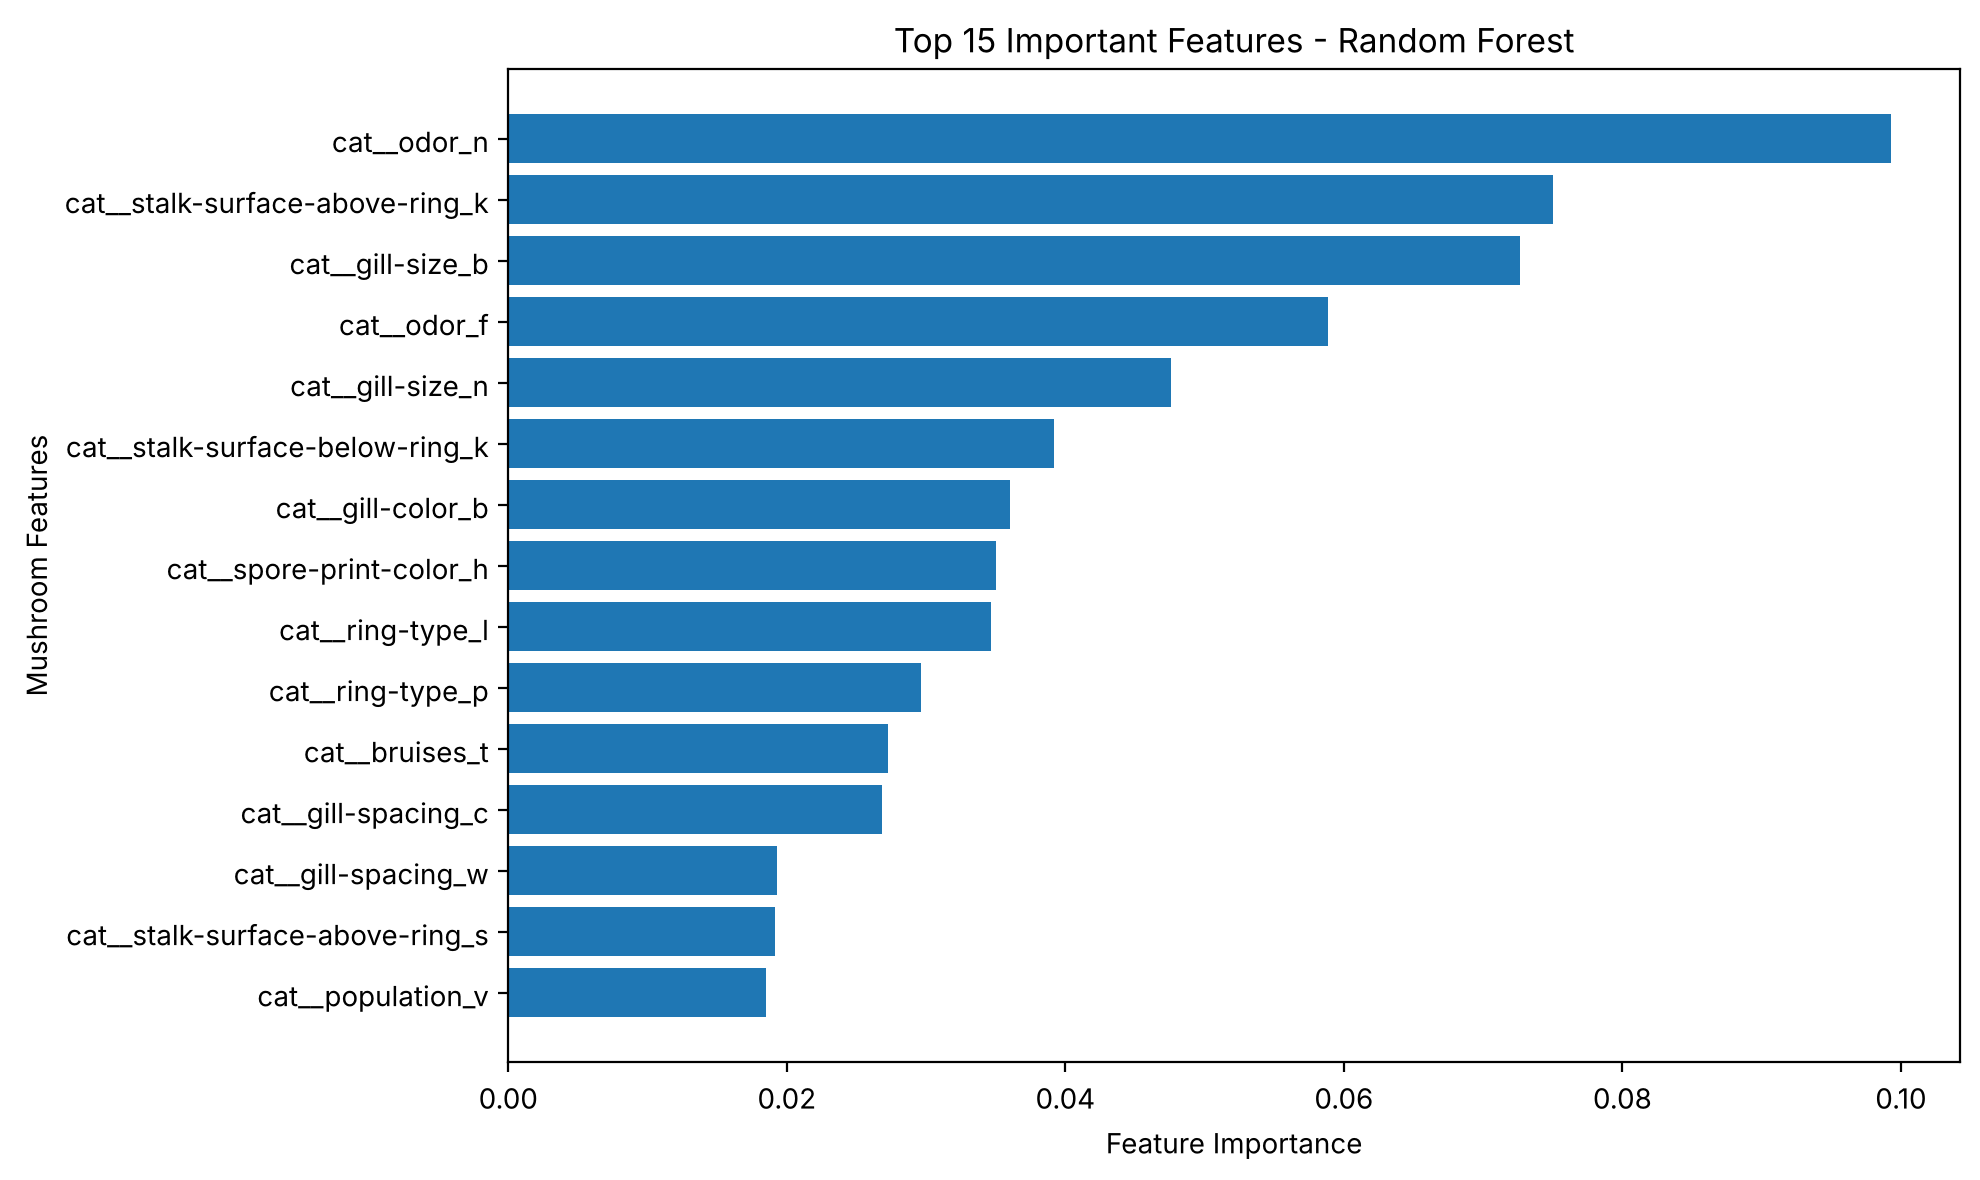

In [48]:
import pandas as pd
import matplotlib.pyplot as plt

# Get the best Random Forest model
best_rf = rf_grid.best_estimator_

# Get feature names after one-hot encoding
feature_names = best_rf.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get feature importance scores
importances = best_rf.named_steps[
    "model"
].feature_importances_

# Create a table
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

# Select the 15 most important encoded features
top_features = feature_importance_df.nlargest(
    15, "Importance"
)

# Plot the results
plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Mushroom Features")
plt.title("Top 15 Important Features - Random Forest")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### 8.1 Importance per Original Feature (Aggregated + Permutation)
The chart above ranks individual one-hot columns. Summing them back to the original feature is easier to interpret. Permutation importance (accuracy drop when a feature is shuffled) is also shown, as impurity-based importance can be biased toward features with many categories.

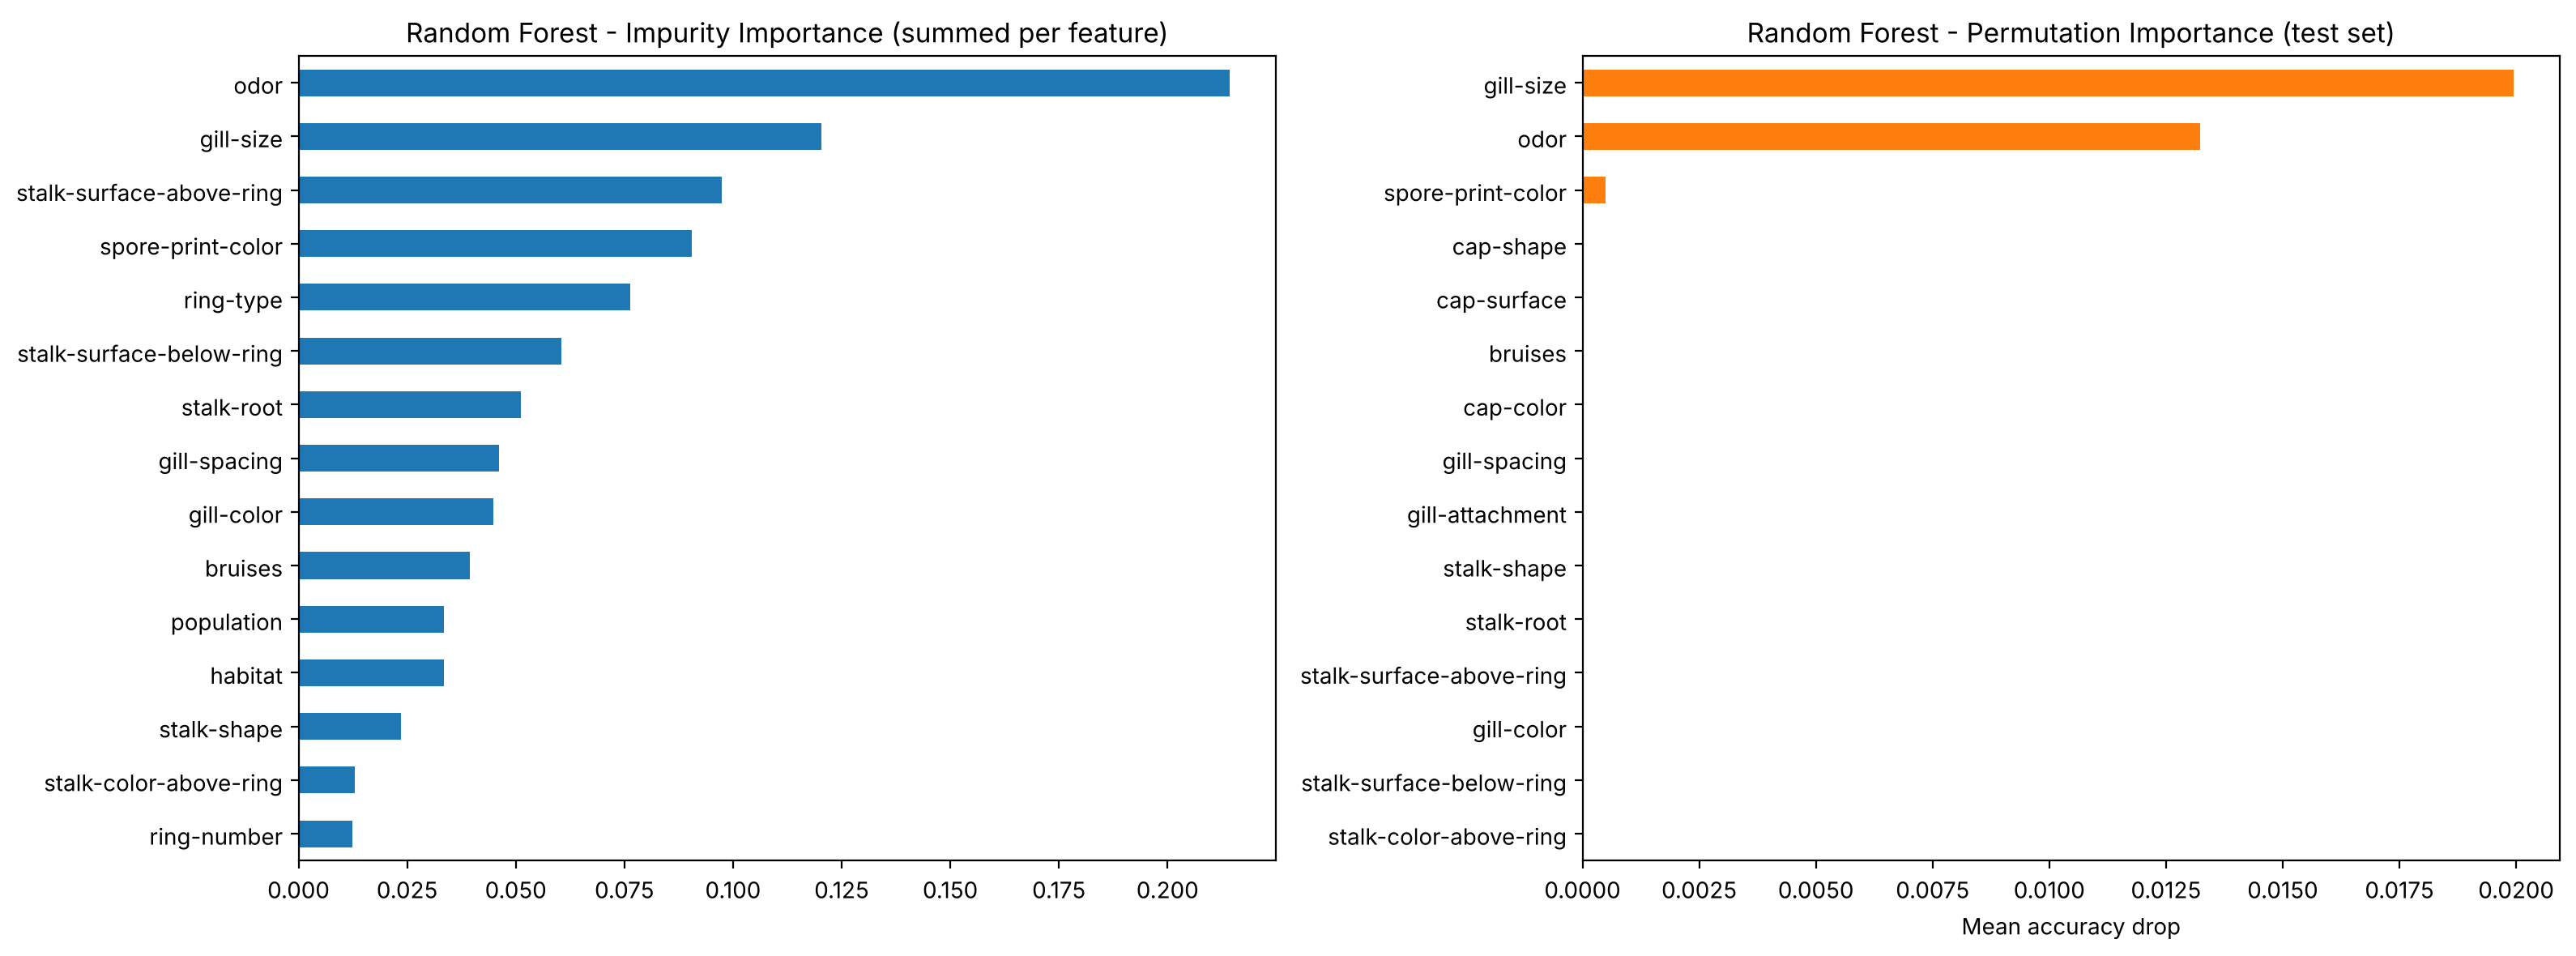

In [49]:
from sklearn.inspection import permutation_importance

orig_names = [n.replace("cat__", "").rsplit("_", 1)[0] for n in feature_names]
agg_importance = (pd.Series(importances, index=orig_names)
                    .groupby(level=0).sum().sort_values(ascending=False))

perm = permutation_importance(best_rf, X_test, y_test, n_repeats=10,
                              random_state=42, n_jobs=-1)
perm_importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
agg_importance.head(15).iloc[::-1].plot(kind="barh", ax=axes[0])
axes[0].set_title("Random Forest - Impurity Importance (summed per feature)")
perm_importance.head(15).iloc[::-1].plot(kind="barh", ax=axes[1], color="tab:orange")
axes[1].set_title("Random Forest - Permutation Importance (test set)")
axes[1].set_xlabel("Mean accuracy drop")
plt.tight_layout()
plt.show()

In [50]:
# Save feature importance results to CSV
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

feature_importance_df.to_csv(
    "feature_importance.csv",
    index=False
)

print("Feature importance saved successfully!")

Feature importance saved successfully!


In [51]:
# Save final model comparison results
comparison_df.to_csv(
    "model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [52]:
# Save the cleaned mushroom dataset
df_clean.to_csv("mushrooms_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Dataset shape:", df_clean.shape)

Cleaned dataset saved successfully!
Dataset shape: (8124, 22)


## 9. Model Saving and Verification

In [53]:
import joblib

# Select the best tuned Logistic Regression model
final_model = logreg_grid.best_estimator_

# Save the complete model, including preprocessing
joblib.dump(final_model, "best_mushroom_model.pkl")

print("Best model saved successfully!")

Best model saved successfully!


In [54]:
import joblib
from sklearn.metrics import accuracy_score

# Load the saved model
loaded_model = joblib.load("best_mushroom_model.pkl")

# Make predictions using the loaded model
loaded_predictions = loaded_model.predict(X_test)

# Check accuracy
loaded_accuracy = accuracy_score(y_test, loaded_predictions)

print("Saved model loaded successfully!")
print("Loaded Model Accuracy:", loaded_accuracy)

# Compare predictions with the original model
original_predictions = final_model.predict(X_test)

print(
    "Predictions match original model:",
    (loaded_predictions == original_predictions).all()
)

Saved model loaded successfully!
Loaded Model Accuracy: 1.0
Predictions match original model: True


In [55]:
from pathlib import Path

required_files = [
    "mushrooms.csv",
    "mushrooms_cleaned.csv",
    "mushroom_analysis.ipynb",
    "feature_importance.csv",
    "model_comparison.csv",
    "best_mushroom_model.pkl"
]

print("FINAL PROJECT FILE CHECK")
print("-" * 35)

for filename in required_files:
    if Path(filename).exists():
        print(f"[OK] {filename}")
    else:
        print(f"[MISSING] {filename}")

print("\nTotal files checked:", len(required_files))

FINAL PROJECT FILE CHECK
-----------------------------------
[OK] mushrooms.csv
[OK] mushrooms_cleaned.csv
[OK] mushroom_analysis.ipynb
[OK] feature_importance.csv
[OK] model_comparison.csv
[OK] best_mushroom_model.pkl

Total files checked: 6


## 10. Robustness Analysis

> **Note:** these folds use the same `random_state` as the folds used during grid search, so this check is **optimistic** (the parameters were chosen on the same data). The held-out test set results in Section 7 are the unbiased estimate.

In [56]:
from sklearn.model_selection import StratifiedKFold, cross_validate
import pandas as pd

# Set up 5-fold stratified cross-validation
robustness_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate the tuned Logistic Regression configuration
robustness_scores = cross_validate(
    logreg_grid.best_estimator_,
    X_train,
    y_train,
    cv=robustness_cv,
    scoring={
        "Accuracy": "accuracy",
        "Precision": "precision_macro",
        "Recall": "recall_macro",
        "F1": "f1_macro"
    },
    n_jobs=-1
)

# Display results
robustness_df = pd.DataFrame({
    "Fold": [1, 2, 3, 4, 5],
    "Accuracy": robustness_scores["test_Accuracy"],
    "Precision": robustness_scores["test_Precision"],
    "Recall": robustness_scores["test_Recall"],
    "F1-score": robustness_scores["test_F1"]
})

print("LOGISTIC REGRESSION ROBUSTNESS RESULTS")
display(robustness_df)

print("\nMean Accuracy:", robustness_df["Accuracy"].mean())
print("Accuracy Standard Deviation:", robustness_df["Accuracy"].std())

LOGISTIC REGRESSION ROBUSTNESS RESULTS


,Fold,Accuracy,Precision,Recall,F1-score
0,1,1.0,1.0,1.0,1.0
1,2,1.0,1.0,1.0,1.0
2,3,1.0,1.0,1.0,1.0
3,4,1.0,1.0,1.0,1.0
4,5,1.0,1.0,1.0,1.0



Mean Accuracy: 1.0
Accuracy Standard Deviation: 0.0


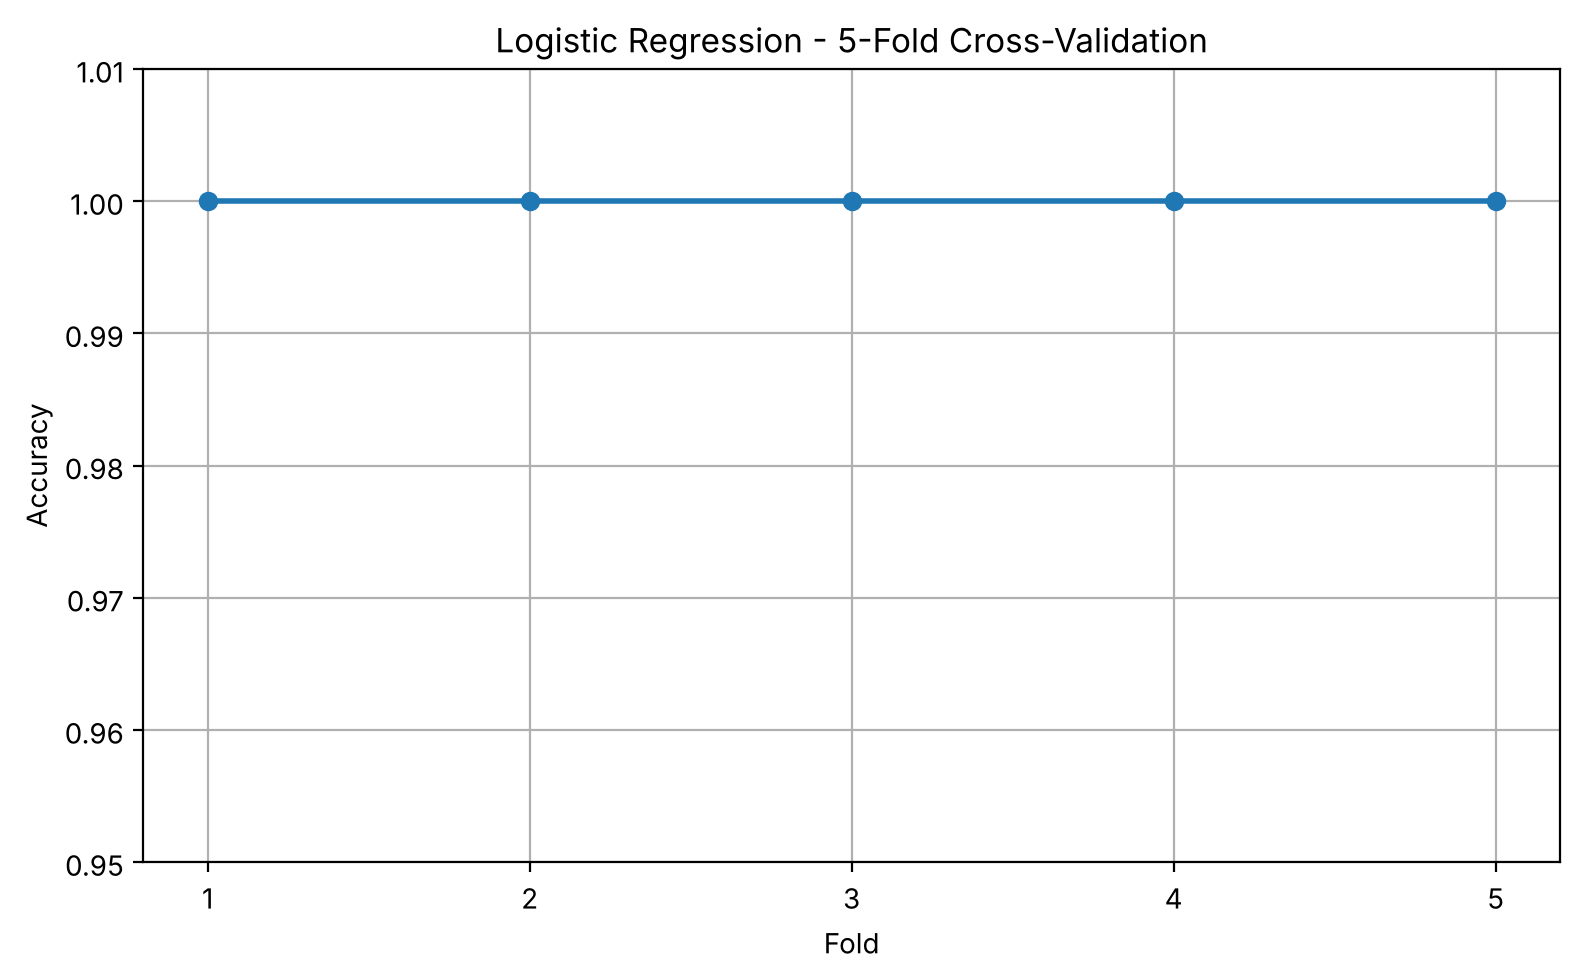

In [57]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    robustness_df["Fold"],
    robustness_df["Accuracy"],
    marker="o",
    linewidth=2
)

plt.title("Logistic Regression - 5-Fold Cross-Validation")
plt.xlabel("Fold")
plt.ylabel("Accuracy")

plt.xticks([1, 2, 3, 4, 5])
plt.ylim(0.95, 1.01)
plt.grid(True)

plt.tight_layout()
plt.show()

## 11. Why Every Model Scores 100% — Harder Scenario Experiment
The full dataset is almost perfectly separable: **odor alone** classifies most mushrooms correctly (see below). This is why every model reaches 100% and the comparison cannot separate them. To give a meaningful comparison, the same workflow is repeated using only features a person can see **in the field without smelling or spore-printing**: cap shape, cap surface, cap colour, bruises, population and habitat.

In [58]:
# Baseline: odor as the only feature
odor_only = Pipeline([
    ("enc", OneHotEncoder(handle_unknown="ignore")),
    ("model", LogisticRegression(max_iter=1000, random_state=42)),
])
odor_scores = cross_val_score(odor_only, X_train[["odor"]], y_train, cv=cv)
print(f"Odor-only CV accuracy: {odor_scores.mean():.4f}")
print(f"Odor-only test accuracy: {odor_only.fit(X_train[['odor']], y_train).score(X_test[['odor']], y_test):.4f}")

Odor-only CV accuracy: 0.9851
Odor-only test accuracy: 0.9858


In [59]:
FIELD_FEATURES = ["cap-shape", "cap-surface", "cap-color",
                  "bruises", "population", "habitat"]

Xf_train, Xf_test = X_train[FIELD_FEATURES], X_test[FIELD_FEATURES]

field_pre = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), FIELD_FEATURES)
])

field_models = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000, random_state=42),
        {"model__C": [0.01, 0.1, 1, 10, 100]}),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=42),
        {"model__max_depth": [3, 5, 10, None],
         "model__min_samples_leaf": [1, 2, 5, 10],
         "model__criterion": ["gini", "entropy"]}),
    "Random Forest": (
        RandomForestClassifier(random_state=42, n_jobs=-1),
        {"model__n_estimators": [100, 300],
         "model__max_depth": [5, 10, None],
         "model__min_samples_leaf": [1, 2, 5]}),
}

field_rows, field_best = [], {}
for name, (est, grid_params) in field_models.items():
    pipe = Pipeline([("preprocessor", field_pre), ("model", est)])
    default_cv = cross_val_score(pipe, Xf_train, y_train, cv=cv).mean()
    g = GridSearchCV(pipe, grid_params, cv=cv, scoring="neg_log_loss", n_jobs=-1)
    g.fit(Xf_train, y_train)
    field_best[name] = g.best_estimator_
    tuned_cv = cross_val_score(g.best_estimator_, Xf_train, y_train, cv=cv).mean()
    field_rows.append({"Model": name, "Default CV Acc": round(default_cv, 4),
                       "Tuned CV Acc": round(tuned_cv, 4),
                       "Best Params": g.best_params_})

field_tuning_df = pd.DataFrame(field_rows).sort_values("Tuned CV Acc", ascending=False)
field_tuning_df

,Model,Default CV Acc,Tuned CV Acc,Best Params
1,Decision Tree,0.9832,0.9832,"{'model__criterion': 'gini', 'model__max_depth': None, 'model__min_samples_leaf': 1}"
2,Random Forest,0.9831,0.9828,"{'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 300}"
0,Logistic Regression,0.8995,0.9098,{'model__C': 100}


The two models with the highest tuned CV accuracy are combined in a soft-voting ensemble; the lowest-scoring model is excluded. The selection is done in code from the CV results, not from the test set.

In [60]:
top_two = field_tuning_df["Model"].head(2).tolist()
excluded = field_tuning_df["Model"].iloc[2]
print("Ensemble members:", top_two, "| Excluded:", excluded)

field_ensemble = VotingClassifier(
    estimators=[(n.replace(" ", "_").lower(), field_best[n]) for n in top_two],
    voting="soft")
field_ensemble.fit(Xf_train, y_train)

field_all = {**field_best, "Ensemble (Soft Voting)": field_ensemble}

rows = []
for name, model in field_all.items():
    pred = model.predict(Xf_test)
    proba = model.predict_proba(Xf_test)[:, list(model.classes_).index("p")]
    rows.append({
        "Model": name,
        "Train Acc": model.score(Xf_train, y_train),
        "Test Acc": accuracy_score(y_test, pred),
        "Precision (p)": precision_score(y_test, pred, pos_label="p"),
        "Recall (p)": recall_score(y_test, pred, pos_label="p"),
        "F1 (p)": f1_score(y_test, pred, pos_label="p"),
        "ROC-AUC": roc_auc_score(y_test_bin, proba),
        "Poisonous called edible": int(((y_test == "p") & (pred == "e")).sum()),
    })
field_comparison_df = pd.DataFrame(rows).round(4)
field_comparison_df

Ensemble members: ['Decision Tree', 'Random Forest'] | Excluded: Logistic Regression


,Model,Train Acc,Test Acc,Precision (p),Recall (p),F1 (p),ROC-AUC,Poisonous called edible
0,Logistic Regression,0.9101,0.9089,0.9024,0.9093,0.9059,0.9500,71
1,Decision Tree,0.9849,0.9809,0.9653,0.9962,0.9805,0.9982,3
2,Random Forest,0.9849,0.9815,0.9665,0.9962,0.9811,0.9988,3
3,Ensemble (Soft Voting),0.9849,0.9809,0.9653,0.9962,0.9805,0.9989,3


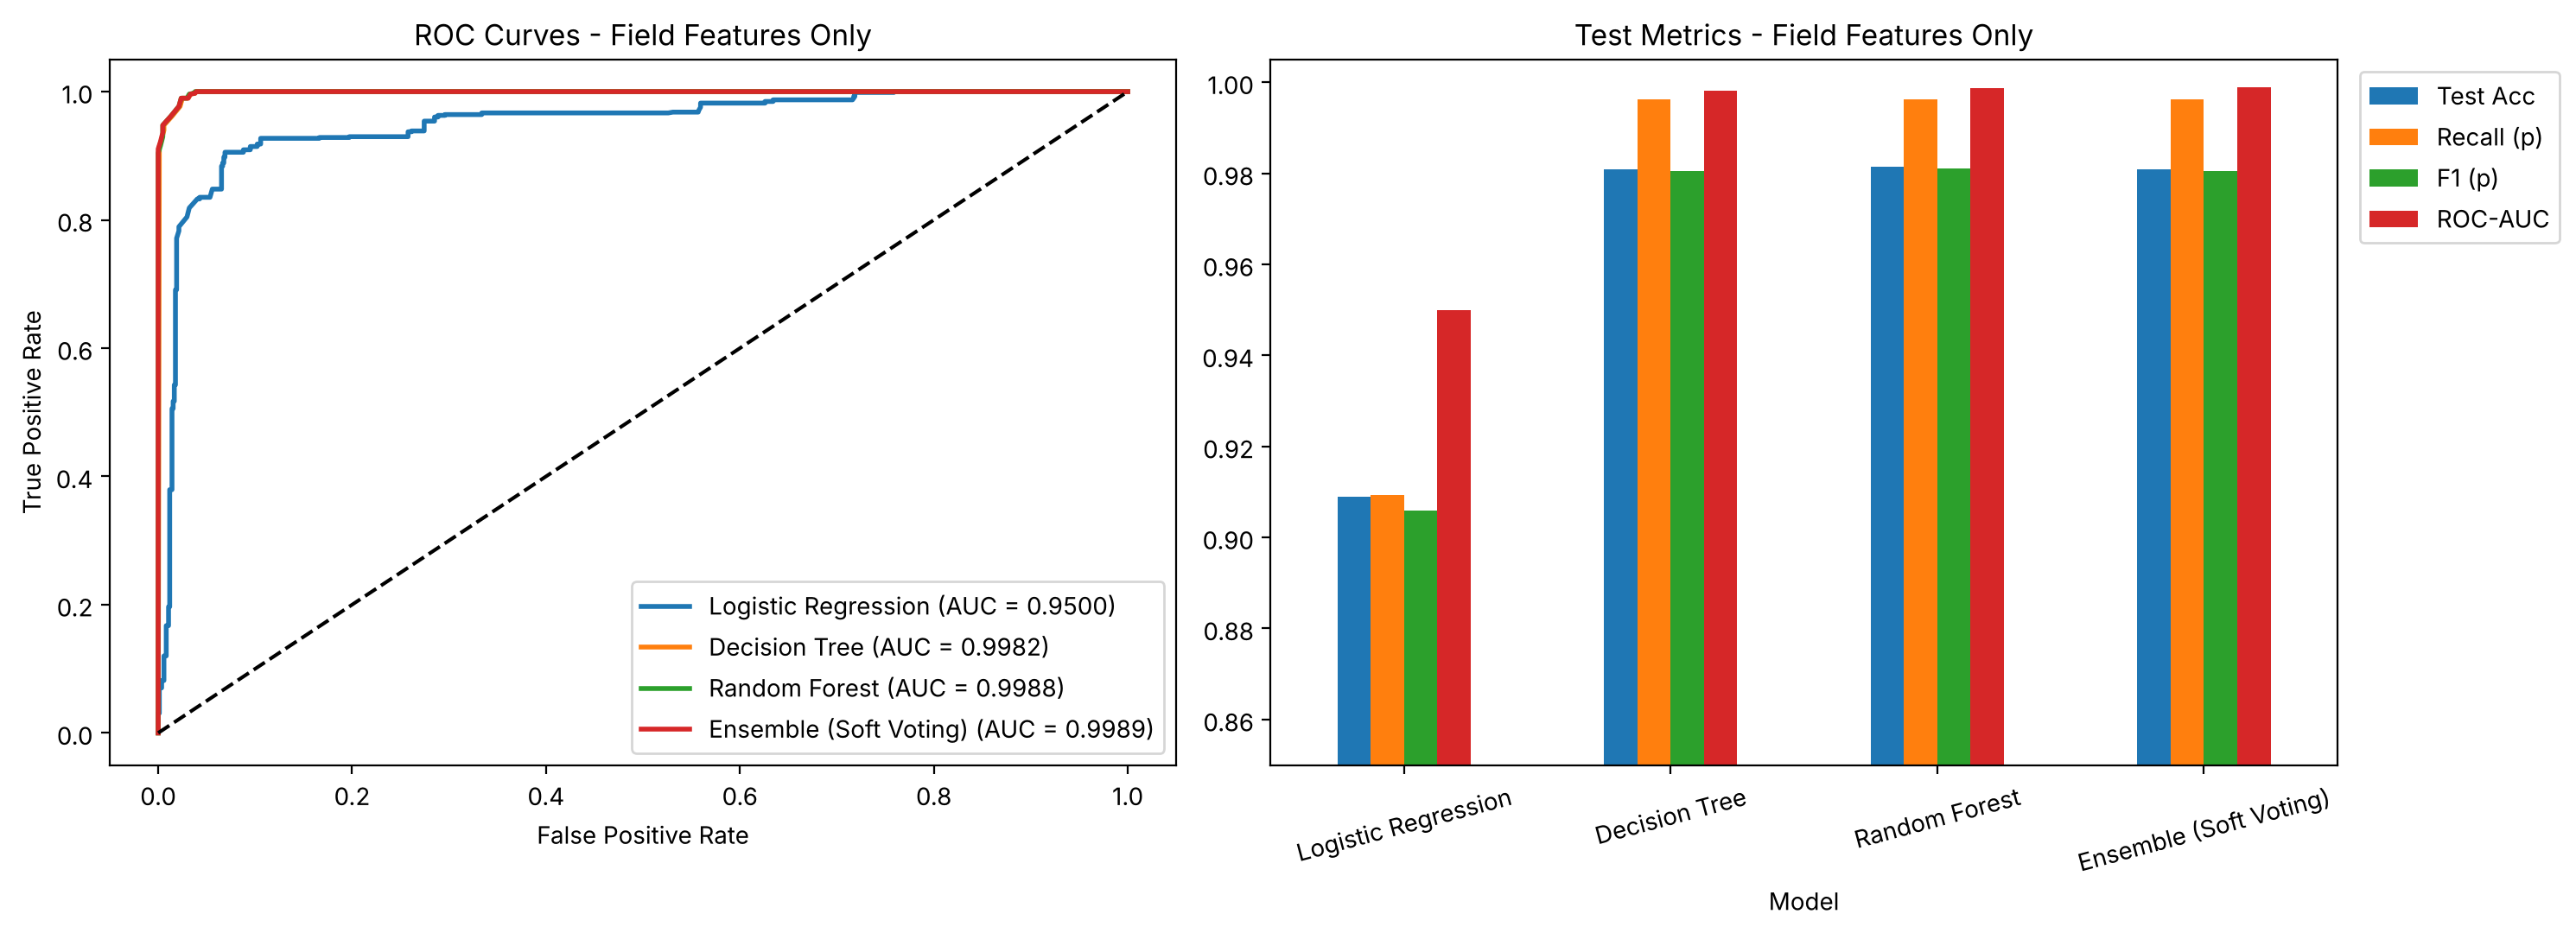

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

for name, model in field_all.items():
    proba = model.predict_proba(Xf_test)[:, list(model.classes_).index("p")]
    fpr, tpr, _ = roc_curve(y_test_bin, proba)
    axes[0].plot(fpr, tpr, linewidth=2,
                 label=f"{name} (AUC = {roc_auc_score(y_test_bin, proba):.4f})")
axes[0].plot([0, 1], [0, 1], "k--")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curves - Field Features Only")
axes[0].legend(loc="lower right")

field_comparison_df.set_index("Model")[["Test Acc", "Recall (p)", "F1 (p)", "ROC-AUC"]].plot(
    kind="bar", ax=axes[1], ylim=(0.85, 1.005))
axes[1].set_title("Test Metrics - Field Features Only")
axes[1].tick_params(axis="x", rotation=15)
axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

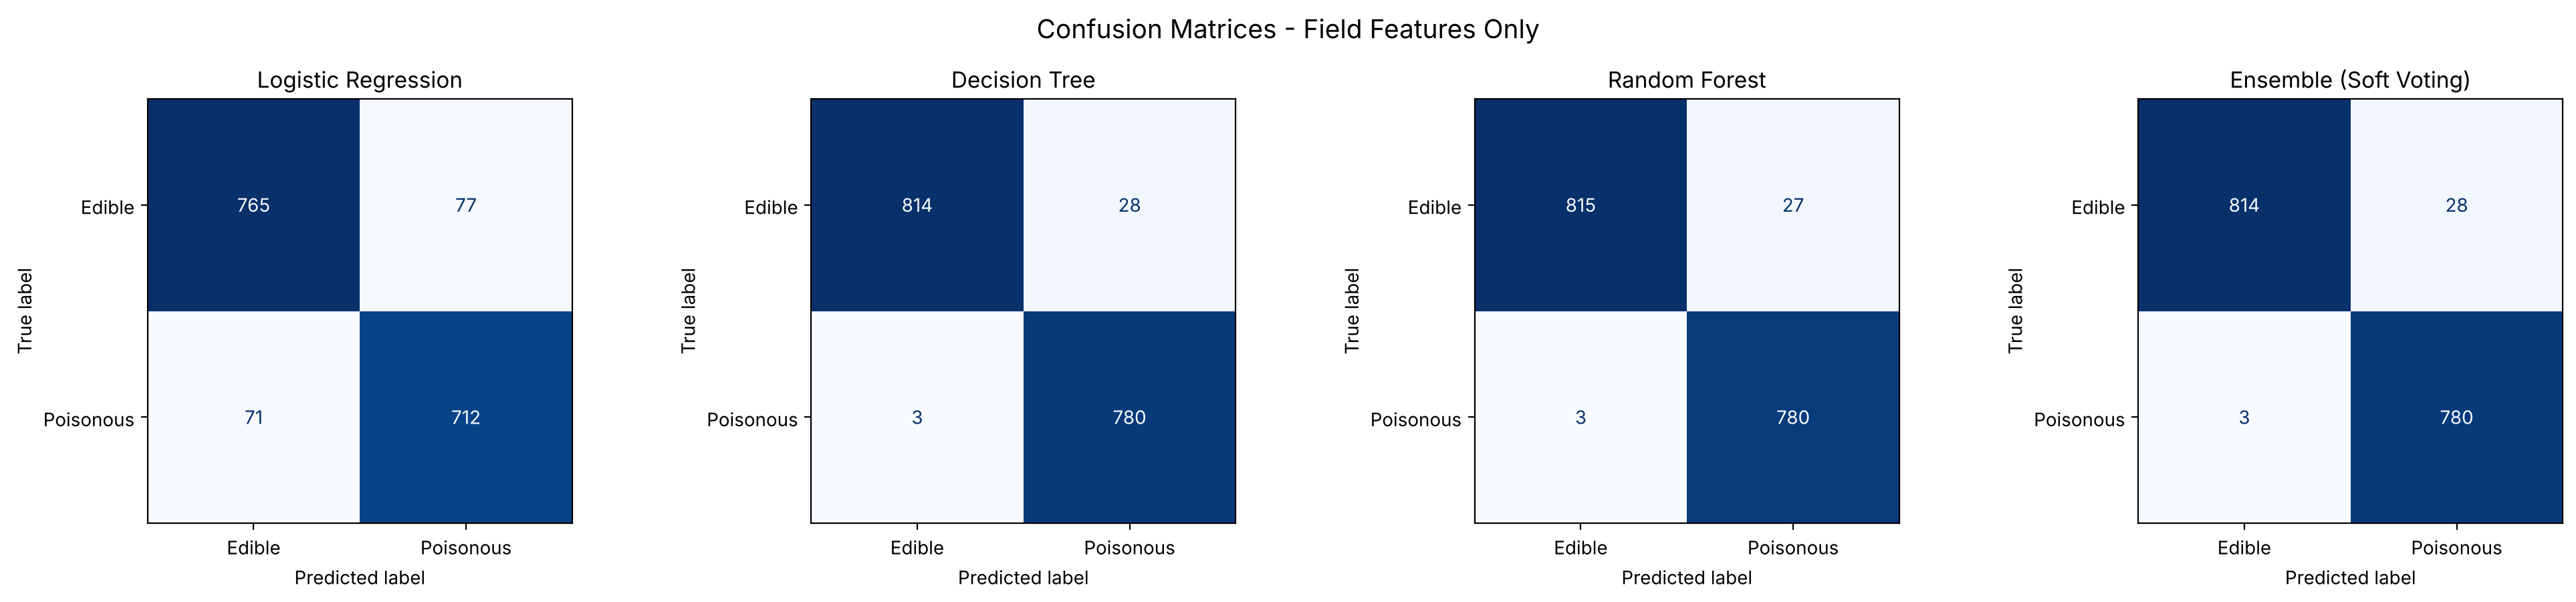

,Ensemble vs,Ensemble right / model wrong,Model right / ensemble wrong,p-value,Significant at 0.05?
0,Logistic Regression,125,8,0.0,True
1,Decision Tree,0,0,1.0,False
2,Random Forest,0,1,1.0,False


In [62]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (name, model) in zip(axes, field_all.items()):
    ConfusionMatrixDisplay.from_estimator(
        model, Xf_test, y_test, labels=["e", "p"],
        display_labels=["Edible", "Poisonous"], cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name)
plt.suptitle("Confusion Matrices - Field Features Only", fontsize=14)
plt.tight_layout()
plt.show()

ens_pred_f = field_ensemble.predict(Xf_test)
rows = []
for name in field_best:
    b, c, p = mcnemar_exact(y_test.values, ens_pred_f, field_best[name].predict(Xf_test))
    rows.append({"Ensemble vs": name, "Ensemble right / model wrong": b,
                 "Model right / ensemble wrong": c, "p-value": round(p, 4),
                 "Significant at 0.05?": p < 0.05})
pd.DataFrame(rows)

In [63]:
# Save the harder-scenario results alongside the main comparison
field_comparison_df.to_csv("model_comparison_field_features.csv", index=False)
comparison_df.to_csv("model_comparison.csv", index=False)
print("Saved model_comparison.csv (now with ROC-AUC) and model_comparison_field_features.csv")

Saved model_comparison.csv (now with ROC-AUC) and model_comparison_field_features.csv


## 12. Impact of Preprocessing (Ablation)
Each preprocessing decision is compared against an alternative using the same 5-fold stratified CV on the training set. One-hot encoding matters greatly for Logistic Regression; the stalk-root treatment makes no measurable difference on this saturated benchmark.

In [ ]:
# Preprocessing ablation: does each preprocessing choice matter? (5-fold stratified CV, training set only)
from sklearn.preprocessing import OrdinalEncoder

def make_pre(cols, encoding="onehot", impute="constant"):
    imputer = (SimpleImputer(strategy="constant", fill_value="missing") if impute == "constant"
               else SimpleImputer(strategy="most_frequent"))
    encoder = (OneHotEncoder(handle_unknown="ignore") if encoding == "onehot"
               else OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))
    return ColumnTransformer([("cat", Pipeline([("imp", imputer), ("enc", encoder)]), cols)])

ablation_models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}
all_cols = X_train.columns.tolist()
configs = [
    ("All features: one-hot + 'missing' category (adopted)", all_cols, "onehot", "constant"),
    ("All features: one-hot + mode imputation", all_cols, "onehot", "mode"),
    ("All features: stalk-root column dropped", [c for c in all_cols if c != "stalk-root"], "onehot", "constant"),
    ("All features: ordinal encoding", all_cols, "ordinal", "constant"),
    ("Six field features: one-hot (adopted)", FIELD_FEATURES, "onehot", "constant"),
    ("Six field features: ordinal encoding", FIELD_FEATURES, "ordinal", "constant"),
]
rows = []
for label, cols, enc, imp in configs:
    row = {"Configuration": label}
    for name, est in ablation_models.items():
        pipe = Pipeline([("preprocessor", make_pre(cols, enc, imp)), ("model", est)])
        row[name] = round(cross_val_score(pipe, X_train[cols], y_train, cv=cv).mean(), 4)
    rows.append(row)
ablation_df = pd.DataFrame(rows)
print(ablation_df.to_string(index=False))

                                       Configuration  Logistic Regression  Decision Tree  Random Forest
All features: one-hot + 'missing' category (adopted)               0.9994         0.9997         1.0000
             All features: one-hot + mode imputation               0.9994         0.9997         1.0000
             All features: stalk-root column dropped               0.9994         0.9997         1.0000
                      All features: ordinal encoding               0.9554         1.0000         1.0000
               Six field features: one-hot (adopted)               0.8995         0.9832         0.9831
                Six field features: ordinal encoding               0.8372         0.9831         0.9828
